# STRATOS 2023 uPRISM Open Data Tutorial

This notebook complements the Streamlit flight tracker by showing how to
load, inspect, clean, visualize, validate, and export the **Strato-Science
2023 uPRISM dataset** directly with Python.

The 2023 campaign is the most complete supported campaign. It includes:

- estimation-filter data at 1 Hz and 25 Hz;
- optional 500 Hz estimation-filter data during active pointing windows;
- dual-GNSS data;
- IMU, attitude, temperature, and pressure data;
- NMEA records;
- a separate environmental dataset containing CPU temperature, external
  temperature, pressure, and humidity;
- track angle;
- no onboard image dataset.

## Data-quality issues handled

1. GNSS records contain timestamp anomalies near the GPS epoch in 1980.
2. Initial or reset-related GNSS records can contain `(0°, 0°)` coordinates.
3. The navigation sensor was reset during the campaign, so timestamp gaps,
   invalid fixes, and discontinuities must be inspected rather than silently
   joined.
4. Altitude anomalies are evaluated using abrupt local changes, change rates,
   short temporary blocks, and local rolling medians.
5. IMU, environmental, and track-angle plots use only 2023 timestamps.
6. The final exported GNSS1 trajectory is the same spatially cleaned dataframe
   used in the final 2D and 3D plots.
7. The optional 500 Hz file is not loaded unless explicitly enabled.

Raw observations remain unchanged for traceability. Cleaning is applied only
to derived analysis tables.

In [ ]:
import csv
import io
import math
import re
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import urllib3
from IPython.display import display

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 250)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 260)

pandas: 3.0.3
numpy: 2.4.6


## 1. Campaign configuration

The campaign took place on August 22, 2023. A navigation-sensor reset occurred
during the flight, so long gaps and reset-related records should not be treated
as normal consecutive samples.

In [2]:
YEAR = 2023
FLIGHT_DATE = "2023-08-22"
NAVIGATION_RESET_TIME = pd.Timestamp(
    "2023-08-22 07:18:00",
    tz="UTC",
)

DATA_SERVER_ROOT = (
    "https://donnees-data.asc-csa.gc.ca/users/"
    "OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/"
)
BASE_URL = DATA_SERVER_ROOT + "uprism_data_2023/"

FILES = {
    "ef_1hz": ("GQ7_EF_1hz_20230822.csv", "multi"),
    "ef_25hz": ("GQ7_EF_25hz_20230822.csv", "multi"),
    "ef_500hz": ("GQ7_EF_500hz_20230822.csv", "multi"),
    "gnss1": ("GQ7_GNSS1_20230822.csv", "multi"),
    "gnss2": ("GQ7_GNSS2_20230822.csv", "multi"),
    "imu": ("GQ7_IMU_20230822.csv", "multi"),
    "nmea": ("GQ7_NMEA_20230822.csv", "none"),
    "environment": ("PRISM_HW1_env_20230822.csv", "auto"),
    "track": ("SWNAV_AHR0_track_angle_20230822.csv", "auto"),
}

POSITION_JUMP_THRESHOLD_M = 100_000
AUTO_SELECT_LARGEST_SEGMENT = True

# The GNSS Position Valid bit is retained for inspection. It is not enforced
# by default so the tutorial does not silently remove rows before the flag
# distribution is reviewed.
REQUIRE_POSITION_VALID_FLAG = False

# Large/optional files.
LOAD_500_HZ = False
LOAD_NMEA = False

FILES

{'ef_1hz': ('GQ7_EF_1hz_20230822.csv', 'multi'),
 'ef_25hz': ('GQ7_EF_25hz_20230822.csv', 'multi'),
 'ef_500hz': ('GQ7_EF_500hz_20230822.csv', 'multi'),
 'gnss1': ('GQ7_GNSS1_20230822.csv', 'multi'),
 'gnss2': ('GQ7_GNSS2_20230822.csv', 'multi'),
 'imu': ('GQ7_IMU_20230822.csv', 'multi'),
 'nmea': ('GQ7_NMEA_20230822.csv', 'none'),
 'environment': ('PRISM_HW1_env_20230822.csv', 'auto'),
 'track': ('SWNAV_AHR0_track_angle_20230822.csv', 'auto')}

## 2. Robust loading and analysis helpers

In [3]:
def normalize_name(value: object) -> str:
    """Normalize a label for loose column matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


def make_unique(names: list[object]) -> list[str]:
    """Make duplicate or blank header names usable as dataframe columns."""
    counts: dict[str, int] = {}
    output: list[str] = []

    for value in names:
        name = str(value).strip() or "unnamed"
        count = counts.get(name, 0)
        output.append(name if count == 0 else f"{name}_{count}")
        counts[name] = count + 1

    return output


def fetch_text(url: str, timeout: int = 180) -> str:
    """Download a text file from the CSA open-data server."""
    response = requests.get(
        url,
        timeout=timeout,
        verify=False,
        headers={"User-Agent": "STRATOS-uPRISM-tutorial"},
    )
    response.raise_for_status()
    return response.content.decode("utf-8-sig", errors="replace")


def _trim_trailing_empty_fields(row: list[str]) -> list[str]:
    """Remove only empty fields created by trailing delimiters."""
    cleaned = [str(value).strip() for value in row]
    while cleaned and cleaned[-1] == "":
        cleaned.pop()
    return cleaned


def read_uprism_table(
    url: str,
    *,
    header_mode: str = "auto",
) -> pd.DataFrame:
    """Read a uPRISM CSV without shifting columns.

    Some 2022 files have fewer header fields than raw data fields because each
    data row ends with an extra comma. Trailing empty fields are removed before
    alignment. Any remaining extra non-empty fields raise an error rather than
    being silently discarded.
    """
    text = fetch_text(url)

    if header_mode == "none":
        frame = pd.DataFrame({"raw_text": text.splitlines()})
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    parsed_rows = [
        _trim_trailing_empty_fields(row)
        for row in csv.reader(io.StringIO(text))
    ]
    parsed_rows = [row for row in parsed_rows if any(row)]

    if not parsed_rows:
        frame = pd.DataFrame()
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    if header_mode == "single":
        header_index = 0
    elif header_mode == "multi":
        header_index = 1
    elif header_mode == "auto":
        first = {normalize_name(value) for value in parsed_rows[0]}
        second = (
            {normalize_name(value) for value in parsed_rows[1]}
            if len(parsed_rows) > 1
            else set()
        )
        required = {"source", "utctimestamp"}

        if required.issubset(first):
            header_index = 0
        elif required.issubset(second):
            header_index = 1
        else:
            keywords = {
                "source",
                "utctimestamp",
                "packet",
                "latitude",
                "longitude",
                "trackangle",
                "trackanglevalid",
            }
            first_score = len(first.intersection(keywords))
            second_score = len(second.intersection(keywords))
            header_index = 0 if first_score >= second_score else 1
    else:
        raise ValueError(f"Unsupported header_mode: {header_mode}")

    header = make_unique(parsed_rows[header_index])
    width = len(header)

    data_rows: list[list[str]] = []

    for source_row, row in enumerate(
        parsed_rows[header_index + 1:],
        start=header_index + 2,
    ):
        if len(row) < width:
            row = row + [""] * (width - len(row))
        elif len(row) > width:
            raise ValueError(
                "A data row contains more non-empty fields than the header. "
                f"Source row: {source_row}; header width: {width}; "
                f"row width: {len(row)}."
            )
        data_rows.append(row)

    frame = pd.DataFrame(data_rows, columns=header)
    frame.attrs["source_url"] = url
    frame.attrs["header_rows"] = header_index + 1
    return frame


def find_column(
    frame: pd.DataFrame,
    candidates: list[str],
    *,
    required: bool = False,
) -> str | None:
    """Find a column by normalized exact match, then contains match."""
    normalized_to_actual = {
        normalize_name(column): column
        for column in frame.columns
    }

    for candidate in candidates:
        normalized = normalize_name(candidate)
        if normalized in normalized_to_actual:
            return normalized_to_actual[normalized]

    for candidate in candidates:
        normalized = normalize_name(candidate)
        for column in frame.columns:
            if normalized and normalized in normalize_name(column):
                return column

    if required:
        raise KeyError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns: {list(frame.columns)}"
        )
    return None


def numeric(series: pd.Series) -> pd.Series:
    """Convert a series to numeric values, coercing failures to NaN."""
    return pd.to_numeric(series, errors="coerce")


def parse_campaign_timestamp(
    series: pd.Series,
    *,
    flight_date: str,
) -> pd.Series:
    """Parse complete UTC timestamps and time-only values."""
    raw = series.astype(str).str.strip()
    parsed = pd.to_datetime(raw, utc=True, errors="coerce")

    time_only_mask = raw.str.match(
        r"^\d{1,2}:\d{2}(?::\d{2}(?:[.,]\d+)?)?Z?$",
        na=False,
    )
    if not time_only_mask.any():
        return parsed

    base_date = pd.Timestamp(flight_date, tz="UTC").normalize()
    day_offset = 0
    previous_seconds: float | None = None

    for index in raw[time_only_mask].index:
        value = raw.loc[index].rstrip("Z").replace(",", ".")

        if len(value.split(":")) == 2:
            value = f"{value}:00"

        delta = pd.to_timedelta(value, errors="coerce")
        if pd.isna(delta):
            parsed.loc[index] = pd.NaT
            continue

        seconds = float(delta.total_seconds())

        if (
            previous_seconds is not None
            and seconds < previous_seconds - 6 * 3600
        ):
            day_offset += 1

        parsed.loc[index] = (
            base_date
            + pd.Timedelta(days=day_offset)
            + delta
        )
        previous_seconds = seconds

    return parsed


def missing_value_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """Summarize both NaN values and blank strings."""
    normalized = frame.replace(r"^\s*$", np.nan, regex=True)

    summary = pd.DataFrame(
        {
            "column": normalized.columns,
            "missing_rows": [
                int(normalized[column].isna().sum())
                for column in normalized.columns
            ],
            "missing_percent": [
                float(normalized[column].isna().mean() * 100)
                for column in normalized.columns
            ],
        }
    )

    return (
        summary
        .sort_values(
            ["missing_percent", "missing_rows"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def standardize_trajectory(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    require_position_valid_flag: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return complete diagnostics and an initially cleaned trajectory."""
    time_col = find_column(
        frame,
        ["UTC Timestamp", "Timestamp", "Time"],
        required=True,
    )
    lat_col = find_column(frame, ["Latitude", "Lat"], required=True)
    lon_col = find_column(
        frame,
        ["Longitude", "Lon", "Long"],
        required=True,
    )
    altitude_col = find_column(
        frame,
        ["Ellipsoid Height", "Altitude", "MSL Height"],
        required=False,
    )
    position_valid_col = find_column(
        frame,
        ["Position Valid"],
        required=False,
    )

    diagnostics = frame.copy()

    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["latitude_numeric"] = numeric(diagnostics[lat_col])
    diagnostics["longitude_numeric"] = numeric(diagnostics[lon_col])
    diagnostics["altitude_numeric"] = (
        numeric(diagnostics[altitude_col])
        if altitude_col is not None
        else np.nan
    )

    diagnostics["timestamp_year"] = diagnostics["parsed_timestamp"].dt.year
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )
    diagnostics["coordinate_in_range"] = (
        diagnostics["latitude_numeric"].between(-90, 90)
        & diagnostics["longitude_numeric"].between(-180, 180)
    )
    diagnostics["nonzero_coordinate"] = ~(
        (diagnostics["latitude_numeric"] == 0)
        & (diagnostics["longitude_numeric"] == 0)
    )

    if position_valid_col is not None:
        position_valid_value = (
            numeric(diagnostics[position_valid_col])
            .fillna(0)
            .astype("int64")
        )
        diagnostics["lat_lon_valid_flag"] = (
            (position_valid_value & 1) == 1
        )
    else:
        diagnostics["lat_lon_valid_flag"] = True

    validity = (
        diagnostics["parsed_timestamp"].notna()
        & diagnostics["expected_year"]
        & diagnostics["coordinate_in_range"]
        & diagnostics["nonzero_coordinate"]
    )

    if require_position_valid_flag:
        validity &= diagnostics["lat_lon_valid_flag"]

    diagnostics["trajectory_row_valid"] = validity

    cleaned = diagnostics.loc[
        diagnostics["trajectory_row_valid"],
        [
            "original_data_index",
            "original_csv_row",
            "parsed_timestamp",
            "latitude_numeric",
            "longitude_numeric",
            "altitude_numeric",
            "lat_lon_valid_flag",
        ],
    ].copy()

    cleaned.columns = [
        "original_data_index",
        "original_csv_row",
        "timestamp",
        "latitude",
        "longitude",
        "altitude_m",
        "lat_lon_valid_flag",
    ]

    cleaned = cleaned.sort_values("timestamp").reset_index(drop=True)
    return diagnostics, cleaned


EARTH_RADIUS_M = 6_371_000


def haversine_step_m(
    latitude: pd.Series,
    longitude: pd.Series,
) -> pd.Series:
    """Calculate distance from each row to its preceding row."""
    lat1 = np.radians(latitude.shift(1))
    lon1 = np.radians(longitude.shift(1))
    lat2 = np.radians(latitude)
    lon2 = np.radians(longitude)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return pd.Series(
        2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a)),
        index=latitude.index,
    )


def detect_altitude_discontinuities(
    diagnostics: pd.DataFrame,
    *,
    step_threshold_m: float = 1000,
    rate_threshold_mps: float = 100,
    rolling_window: int = 11,
    residual_threshold_m: float = 1500,
    max_temporary_segment_samples: int = 20,
    neighbor_tolerance_m: float = 1000,
    max_gap_seconds: float = 10,
) -> pd.DataFrame:
    """Detect abrupt local altitude changes without using global IQR."""
    work = diagnostics.copy().reset_index(drop=True)
    altitude = numeric(work["altitude_numeric"])
    timestamp = pd.to_datetime(
        work["parsed_timestamp"],
        utc=True,
        errors="coerce",
    )

    time_step_s = timestamp.diff().dt.total_seconds()
    valid_consecutive_step = (
        time_step_s.gt(0)
        & time_step_s.le(max_gap_seconds)
    )

    altitude_step_m = altitude.diff().where(valid_consecutive_step)
    altitude_rate_mps = (
        altitude_step_m
        / time_step_s.where(valid_consecutive_step)
    )

    rolling_median = altitude.rolling(
        rolling_window,
        center=True,
        min_periods=3,
    ).median()
    local_residual = (altitude - rolling_median).abs()

    transition = (
        altitude_step_m.abs().ge(step_threshold_m)
        | altitude_rate_mps.abs().ge(rate_threshold_mps)
    ).fillna(False)

    temporary_segment = pd.Series(
        False,
        index=work.index,
        dtype=bool,
    )

    transition_positions = np.flatnonzero(transition.to_numpy())

    for first, second in zip(
        transition_positions[:-1],
        transition_positions[1:],
    ):
        gap = second - first
        if gap < 1 or gap > max_temporary_segment_samples:
            continue

        before_index = max(first - 1, 0)
        after_index = second

        before_altitude = altitude.iloc[before_index]
        after_altitude = altitude.iloc[after_index]

        if pd.isna(before_altitude) or pd.isna(after_altitude):
            continue

        if abs(after_altitude - before_altitude) <= neighbor_tolerance_m:
            temporary_segment.iloc[first:second + 1] = True

    local_residual_flag = local_residual.ge(
        residual_threshold_m
    ).fillna(False)

    work["time_step_s"] = time_step_s
    work["valid_consecutive_step"] = valid_consecutive_step
    work["altitude_step_m"] = altitude_step_m
    work["altitude_rate_mps"] = altitude_rate_mps
    work["rolling_altitude_median_m"] = rolling_median
    work["local_altitude_residual_m"] = local_residual
    work["sudden_altitude_transition"] = transition
    work["temporary_altitude_segment"] = temporary_segment
    work["local_altitude_disagreement"] = local_residual_flag
    work["altitude_anomaly_candidate"] = (
        transition | temporary_segment
    )

    return work


def segment_trajectory_by_position_jump(
    trajectory: pd.DataFrame,
    *,
    threshold_m: float,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split a trajectory whenever consecutive positions differ too much."""
    segmented = trajectory.copy()

    segmented["position_step_m"] = haversine_step_m(
        segmented["latitude"],
        segmented["longitude"],
    )
    segmented["new_segment"] = (
        segmented["position_step_m"] > threshold_m
    ).fillna(False)
    segmented["segment_id"] = segmented["new_segment"].cumsum()

    summary = (
        segmented
        .groupby("segment_id", as_index=False)
        .agg(
            rows=("segment_id", "size"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            minimum_latitude=("latitude", "min"),
            maximum_latitude=("latitude", "max"),
            minimum_longitude=("longitude", "min"),
            maximum_longitude=("longitude", "max"),
            minimum_altitude=("altitude_m", "min"),
            maximum_altitude=("altitude_m", "max"),
        )
        .sort_values("rows", ascending=False)
        .reset_index(drop=True)
    )

    return segmented, summary


def plot_2d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty:
        print("No trajectory rows are available.")
        return

    plt.figure(figsize=(10, 7))
    plt.plot(
        trajectory["longitude"],
        trajectory["latitude"],
        linewidth=1,
    )
    plt.scatter(
        trajectory["longitude"].iloc[0],
        trajectory["latitude"].iloc[0],
        label="Start",
    )
    plt.scatter(
        trajectory["longitude"].iloc[-1],
        trajectory["latitude"].iloc[-1],
        label="End",
    )
    plt.xlabel("Longitude [degrees]")
    plt.ylabel("Latitude [degrees]")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_3d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty or trajectory["altitude_m"].notna().sum() == 0:
        print("No altitude-enabled trajectory is available.")
        return

    try:
        import plotly.graph_objects as go
    except ImportError:
        print("Install Plotly with: %pip install plotly")
        return

    max_points = 15_000
    step = max(1, math.ceil(len(trajectory) / max_points))
    plot_frame = trajectory.iloc[::step]

    figure = go.Figure(
        data=[
            go.Scatter3d(
                x=plot_frame["longitude"],
                y=plot_frame["latitude"],
                z=plot_frame["altitude_m"],
                mode="lines",
                line={"width": 4},
                name="Flight path",
            )
        ]
    )

    figure.update_layout(
        title=title,
        scene={
            "xaxis_title": "Longitude [degrees]",
            "yaxis_title": "Latitude [degrees]",
            "zaxis_title": "Altitude [m]",
        },
        height=700,
    )
    figure.show()


def prepare_campaign_timeseries(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    time_candidates: list[str] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Create raw diagnostics, timestamp anomalies, and a year-filtered copy."""
    if time_candidates is None:
        time_candidates = ["UTC Timestamp", "Timestamp", "Time"]

    time_col = find_column(
        frame,
        time_candidates,
        required=True,
    )

    diagnostics = frame.copy()
    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["timestamp_year"] = diagnostics["parsed_timestamp"].dt.year
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )

    anomalies = diagnostics[
        diagnostics["parsed_timestamp"].notna()
        & ~diagnostics["expected_year"]
    ].copy()

    cleaned = (
        diagnostics[
            diagnostics["parsed_timestamp"].notna()
            & diagnostics["expected_year"]
        ]
        .sort_values("parsed_timestamp")
        .reset_index(drop=True)
    )

    return diagnostics, anomalies, cleaned


def select_final_trajectory_segment(
    trajectory: pd.DataFrame,
    *,
    position_jump_threshold_m: float,
    auto_select_largest: bool = True,
    selected_segment_id: int = 0,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    int,
]:
    """Segment a trajectory and return its final selected continuous segment."""
    segmented, segment_summary = segment_trajectory_by_position_jump(
        trajectory,
        threshold_m=position_jump_threshold_m,
    )

    segmented["position_step_km"] = (
        segmented["position_step_m"] / 1000
    )
    segmented["time_step_s"] = (
        segmented["timestamp"].diff().dt.total_seconds()
    )
    segmented["horizontal_speed_mps"] = (
        segmented["position_step_m"]
        / segmented["time_step_s"].replace(0, np.nan)
    )

    jump_candidates = segmented[
        segmented["position_step_m"] > position_jump_threshold_m
    ].copy()

    if segment_summary.empty:
        raise RuntimeError("No trajectory segments are available.")

    if auto_select_largest:
        chosen_segment_id = int(
            segment_summary.iloc[0]["segment_id"]
        )
    else:
        chosen_segment_id = int(selected_segment_id)

    final_trajectory = (
        segmented[
            segmented["segment_id"] == chosen_segment_id
        ]
        .drop(
            columns=[
                "position_step_m",
                "new_segment",
                "segment_id",
                "position_step_km",
                "time_step_s",
                "horizontal_speed_mps",
            ],
            errors="ignore",
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return (
        final_trajectory,
        segmented,
        segment_summary,
        jump_candidates,
        chosen_segment_id,
    )

### Helper sanity checks

These tests verify blank-value handling and trailing-delimiter cleanup.

In [4]:
_test_missing = pd.DataFrame({"a": ["", "1", None]})
assert missing_value_summary(_test_missing).loc[0, "missing_rows"] == 2

_test_row = _trim_trailing_empty_fields(["a", "b", ""])
assert _test_row == ["a", "b"]

print("Helper checks passed.")

Helper checks passed.


## 3. Load the main 2023 files

The 500 Hz EF file and NMEA file are optional. The main tutorial loads GNSS1,
GNSS2, EF 25 Hz, IMU, the separate environmental file, and track angle.

In [5]:
keys_to_load = [
    "gnss1",
    "gnss2",
    "ef_25hz",
    "imu",
    "environment",
    "track",
]

if LOAD_NMEA:
    keys_to_load.append("nmea")

if LOAD_500_HZ:
    keys_to_load.append("ef_500hz")

tables: dict[str, pd.DataFrame] = {}

for key in keys_to_load:
    filename, header_mode = FILES[key]
    url = urljoin(BASE_URL, filename)

    print(f"Loading {key}: {filename}")

    tables[key] = read_uprism_table(
        url,
        header_mode=header_mode,
    )

    print("  shape:", tables[key].shape)
    print("  header rows:", tables[key].attrs.get("header_rows"))

gnss1 = tables["gnss1"]
gnss2 = tables["gnss2"]
ef_25hz = tables["ef_25hz"]
imu = tables["imu"]
environment = tables["environment"]
track = tables["track"]

Loading gnss1: GQ7_GNSS1_20230822.csv
  shape: (40675, 66)
  header rows: 2
Loading gnss2: GQ7_GNSS2_20230822.csv
  shape: (40674, 66)
  header rows: 2
Loading ef_25hz: GQ7_EF_25hz_20230822.csv
  shape: (507444, 30)
  header rows: 2
Loading imu: GQ7_IMU_20230822.csv
  shape: (20335, 26)
  header rows: 2
Loading environment: PRISM_HW1_env_20230822.csv
  shape: (10172, 7)
  header rows: 1
Loading track: SWNAV_AHR0_track_angle_20230822.csv
  shape: (20336, 5)
  header rows: 1


## 4. Inspect raw tables and headers

In [6]:
for key, frame in tables.items():
    print("\n" + "=" * 100)
    print(key, frame.shape)
    print("Columns:")
    print(list(frame.columns))
    display(frame.head(8))


gnss1 (40675, 66)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Latitude', 'Longitude', 'Ellipsoid Height', 'MSL Height', 'Horizontal Accuracy', 'Vertical Accuracy', 'Position Valid', 'North Velocity', 'East Velocity', 'Down Velocity', 'Speed', 'Ground Speed', 'Heading', 'Speed Accuracy', 'Heading Accuracy', 'NED VEL Valid', 'gdop', 'pdop', 'hdop', 'vdop', 'tdop', 'ndop', 'edop', 'dop valid', 'Year', 'Month', 'Day', 'Hour', 'Min', 'Sec', 'mSec', 'UTC Valid', 'TOW', 'Week Num', 'GPS Time Valid Flag', 'Bias', 'Drift', 'Bias Accuracy', 'Drift Accuracy', 'Clock Info 2 Valid', 'Fix Type', 'Num Sats', 'Fix Flag', 'Fix Valid', 'Hardware State', 'Antenna State', 'Antenna Power', 'Hardware Valid', 'Leap Seconds', 'Leap Seconds Valid', 'SBAS TOW', 'SBAS Week Num', 'SBAS System', 'SBAS Id', 'SBAS Count', 'SBAS Status', 'SBAS Valid', 'L1 Jamming State', 'L1 Spoofing State', 'L1 RF Valid', 'L2 Jamming State', 'L2 Spoofing State', 'L2 RF Valid']


,Source,UTC Timestamp,Packet,Latitude,Longitude,Ellipsoid Height,MSL Height,Horizontal Accuracy,Vertical Accuracy,Position Valid,North Velocity,East Velocity,Down Velocity,Speed,Ground Speed,Heading,Speed Accuracy,Heading Accuracy,NED VEL Valid,gdop,pdop,hdop,vdop,tdop,ndop,edop,dop valid,Year,Month,Day,Hour,Min,Sec,mSec,UTC Valid,TOW,Week Num,GPS Time Valid Flag,Bias,Drift,Bias Accuracy,Drift Accuracy,Clock Info 2 Valid,Fix Type,Num Sats,Fix Flag,Fix Valid,Hardware State,Antenna State,Antenna Power,Hardware Valid,Leap Seconds,Leap Seconds Valid,SBAS TOW,SBAS Week Num,SBAS System,SBAS Id,SBAS Count,SBAS Status,SBAS Valid,L1 Jamming State,L1 Spoofing State,L1 RF Valid,L2 Jamming State,L2 Spoofing State,L2 RF Valid
0,LOGQ7,2023-08-22 04:00:00.000,GQ7_GNSS1,48.5699579,-81.36759529999999,259.902,298.438,0.5389999747276306,1.284999966621399,31,-0.019999999552965164,-0.05999999865889549,-0.04999999701976776,0.07999999821186066,0.05999999865889549,89.84043884277344,0.20999999344348907,134.5335693359375,63,2.259999990463257,1.96999990940094,1.0299999713897705,1.6799999475479126,1.100000023841858,0.7599999904632568,0.6899999976158142,127,2023,8,22,4,0,0,0,3,187218.000255832,2276,3,0.000744174,2.77e-07,3.0000000000000004e-09,7.5e-10,15,0,9,1,7,1,4,1,7,18,2,187218.0,2276,1,131,32,7,63,2,1,7,2,1,7
1,LOGQ7,2023-08-22 04:00:00.500,GQ7_GNSS1,48.5699578,-81.3675956,259.857,298.39300000000003,0.5429999828338623,1.309000015258789,31,-0.029999999329447746,-0.04999999701976776,0.03999999910593033,0.07000000029802322,0.05999999865889549,89.84043884277344,0.20999999344348907,147.9971160888672,63,,,,,,,,,2023,8,22,4,0,0,500,3,187218.500255694,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,LOGQ7,2023-08-22 04:00:01.000,GQ7_GNSS1,48.5699579,-81.3675957,259.854,298.39,0.5479999780654907,1.3289999961853027,31,0.04999999701976776,0.0,0.019999999552965164,0.04999999701976776,0.04999999701976776,89.84043884277344,0.1599999964237213,122.78683471679688,63,2.490000009536743,2.1499998569488525,1.090000033378601,1.8499999046325684,1.2599999904632568,0.8399999737739563,0.6899999976158142,127,2023,8,22,4,0,1,0,3,187219.000255555,2276,3,0.000744451,2.77e-07,3.0000000000000004e-09,7.52e-10,15,0,8,1,7,1,4,1,7,18,2,187219.008,2276,1,131,32,7,63,2,1,7,2,1,7
3,LOGQ7,2023-08-22 04:00:01.500,GQ7_GNSS1,48.569958,-81.36759579999999,259.838,298.375,0.5490000247955322,1.343999981880188,31,-0.019999999552965164,-0.07999999821186066,0.029999999329447746,0.08999999612569809,0.07999999821186066,89.84043884277344,0.14000000059604645,90.78173828125,63,,,,,,,,,2023,8,22,4,0,1,500,3,187219.500255417,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,LOGQ7,2023-08-22 04:00:02.000,GQ7_GNSS1,48.569958199999995,-81.3675962,259.922,298.458,0.5479999780654907,1.3370000123977661,31,0.04999999701976776,-0.04999999701976776,-0.03999999910593033,0.07999999821186066,0.07000000029802322,89.84043884277344,0.17999999225139618,97.39891815185547,63,2.490000009536743,2.1499998569488525,1.090000033378601,1.8499999046325684,1.2599999904632568,0.8399999737739563,0.6899999976158142,127,2023,8,22,4,0,2,0,3,187220.000255279,2276,3,0.0007447290000000001,2.7800000000000003e-07,3.0000000000000004e-09,6.56e-10,15,0,8,1,7,1,4,1,7,18,2,187220.0,2276,1,131,32,7,63,2,1,7,2,1,7
5,LOGQ7,2023-08-22 04:00:02.500,GQ7_GNSS1,48.5699584,-81.3675963,259.927,298.463,0.5450000166893005,1.3140000104904175,31,0.0,0.019999999552965164,-0.029999999329447746,0.029999999329447746,0.019999999552965164,89.84043884277344,0.1899999976158142,180.0,63,,,,,,,,,2023,8,22,4,0,2,500,3,187220.50025514,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
6,LOGQ7,2023-08-22 04:00:03.000,GQ7_GNSS1,48.5699586,-81.3675961,259.934,298.47,0.5429999828338623,1.2929999828338623,31,0.029999999329447746,0.029999999329447746,0.009999999776482582,0.03999999910593033,0.03999999910593033,89.84043884277344,0.12999999523162842,146.55589294433594,63,2.490000009536743,2.1499998569488525,1.090000033378601,1.8499999046325684,1.2599999904632568,0.8399999737739563,0.6899999976158142,127,2023,8,22,4,0,3,0


gnss2 (40674, 66)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Latitude', 'Longitude', 'Ellipsoid Height', 'MSL Height', 'Horizontal Accuracy', 'Vertical Accuracy', 'Position Valid', 'North Velocity', 'East Velocity', 'Down Velocity', 'Speed', 'Ground Speed', 'Heading', 'Speed Accuracy', 'Heading Accuracy', 'NED VEL Valid', 'gdop', 'pdop', 'hdop', 'vdop', 'tdop', 'ndop', 'edop', 'dop valid', 'Year', 'Month', 'Day', 'Hour', 'Min', 'Sec', 'mSec', 'UTC Valid', 'TOW', 'Week Num', 'GPS Time Valid Flag', 'Bias', 'Drift', 'Bias Accuracy', 'Drift Accuracy', 'Clock Info 2 Valid', 'Fix Type', 'Num Sats', 'Fix Flag', 'Fix Valid', 'Hardware State', 'Antenna State', 'Antenna Power', 'Hardware Valid', 'Leap Seconds', 'Leap Seconds Valid', 'SBAS TOW', 'SBAS Week Num', 'SBAS System', 'SBAS Id', 'SBAS Count', 'SBAS Status', 'SBAS Valid', 'L1 Jamming State', 'L1 Spoofing State', 'L1 RF Valid', 'L2 Jamming State', 'L2 Spoofing State', 'L2 RF Valid']


,Source,UTC Timestamp,Packet,Latitude,Longitude,Ellipsoid Height,MSL Height,Horizontal Accuracy,Vertical Accuracy,Position Valid,North Velocity,East Velocity,Down Velocity,Speed,Ground Speed,Heading,Speed Accuracy,Heading Accuracy,NED VEL Valid,gdop,pdop,hdop,vdop,tdop,ndop,edop,dop valid,Year,Month,Day,Hour,Min,Sec,mSec,UTC Valid,TOW,Week Num,GPS Time Valid Flag,Bias,Drift,Bias Accuracy,Drift Accuracy,Clock Info 2 Valid,Fix Type,Num Sats,Fix Flag,Fix Valid,Hardware State,Antenna State,Antenna Power,Hardware Valid,Leap Seconds,Leap Seconds Valid,SBAS TOW,SBAS Week Num,SBAS System,SBAS Id,SBAS Count,SBAS Status,SBAS Valid,L1 Jamming State,L1 Spoofing State,L1 RF Valid,L2 Jamming State,L2 Spoofing State,L2 RF Valid
0,LOGQ7,2023-08-22 04:00:00.000,GQ7_GNSS2,48.5699896,-81.3675722,256.3,294.837,1.309000015258789,1.9700000286102295,31,0.04999999701976776,0.019999999552965164,-0.09999999403953552,0.10999999940395355,0.04999999701976776,11.375249862670898,0.3499999940395355,152.15045166015625,63,3.3399999141693115,3.0199999809265137,1.7599999904632568,2.4600000381469727,1.4299999475479126,1.409999966621399,1.0499999523162842,127,2023,8,22,4,0,0,0,3,187217.99961096,2276,3,0.000389044,2.3800000000000001e-07,4e-09,8.07e-10,15,0,5,1,7,1,4,1,7,18,2,187218.0,2276,1,131,34,7,63,2,1,7,2,1,7
1,LOGQ7,2023-08-22 04:00:00.500,GQ7_GNSS2,48.569989799999995,-81.3675722,256.41700000000003,294.95300000000003,1.2999999523162842,1.9839999675750732,31,0.09999999403953552,0.03999999910593033,-0.12999999523162842,0.17000000178813934,0.10999999940395355,11.375249862670898,0.3400000035762787,72.37214660644531,63,,,,,,,,,2023,8,22,4,0,0,499,3,187218.499610841,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,LOGQ7,2023-08-22 04:00:01.000,GQ7_GNSS2,48.5699903,-81.367572,256.481,295.017,1.2920000553131104,1.9980000257492065,31,0.12999999523162842,0.05999999865889549,-0.11999999731779099,0.1899999976158142,0.14999999105930328,11.375249862670898,0.3199999928474426,54.95808792114258,63,3.3399999141693115,3.0199999809265137,1.7599999904632568,2.4600000381469727,1.4299999475479126,1.409999966621399,1.0499999523162842,127,2023,8,22,4,0,1,0,3,187218.999610722,2276,3,0.00038928300000000003,2.3800000000000001e-07,4e-09,8.279999999999999e-10,15,0,5,1,7,1,4,1,7,18,2,187219.008,2276,1,131,34,7,63,2,1,7,2,1,7
3,LOGQ7,2023-08-22 04:00:01.500,GQ7_GNSS2,48.5699907,-81.3675719,256.548,295.084,1.284999966621399,2.013000011444092,31,0.05999999865889549,0.019999999552965164,-0.1599999964237213,0.17000000178813934,0.07000000029802322,11.375249862670898,0.35999998450279236,132.22882080078125,63,,,,,,,,,2023,8,22,4,0,1,499,3,187219.499610603,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,LOGQ7,2023-08-22 04:00:02.000,GQ7_GNSS2,48.569991099999996,-81.36757159999999,256.661,295.198,1.2760000228881836,2.0169999599456787,31,0.17000000178813934,0.11999999731779099,-0.1599999964237213,0.25999999046325684,0.20999999344348907,35.524600982666016,0.3199999928474426,35.20341873168945,63,3.3399999141693115,3.0199999809265137,1.7599999904632568,2.4600000381469727,1.4299999475479126,1.409999966621399,1.0499999523162842,127,2023,8,22,4,0,2,0,3,187219.999610484,2276,3,0.00038952100000000004,2.3800000000000001e-07,4e-09,8.05e-10,15,0,5,1,7,1,4,1,7,18,2,187220.0,2276,1,131,34,7,63,2,1,7,2,1,7
5,LOGQ7,2023-08-22 04:00:02.500,GQ7_GNSS2,48.569991599999994,-81.3675715,256.807,295.344,1.2680000066757202,2.0199999809265137,31,0.11999999731779099,0.019999999552965164,-0.23999999463558197,0.25999999046325684,0.11999999731779099,24.377538681030273,0.3499999940395355,77.93592071533203,63,,,,,,,,,2023,8,22,4,0,2,499,3,187220.499610364,2276,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
6,LOGQ7,2023-08-22 04:00:03.000,GQ7_GNSS2,48.5699918,-81.3675714,256.821,295.357,1.2610000371932983,2.0239999294281006,31,0.029999999329447746,0.009999999776482582,-0.09999999403953552,0.10999999940395355,0.03999999910593033,24.377538681030273,0.3499999940395355,180.0,63,3.3399999141693115,3.0199999809265137,1.7599999904632568,2.4600000381469727,1.4299999475479126,1.40


ef_25hz (507444, 30)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'GPS TOW', 'GPS Weeks', 'GPS Timestamp Valid', 'Latitude', 'Longitude', 'Altitude', 'LLH Valid', 'Velocity North', 'Velocity East', 'Velocity Down', 'Velocity Valid', 'Roll', 'Pitch', 'Yaw', 'Euler Valid', 'Comp Angular Rate X', 'Comp Angular Rate Y', 'Comp Angular Rate Z', 'Comp Angular Rate Valid', 'Linear Acceleration Rate X', 'Linear Acceleration Rate Y', 'Linear Acceleration Rate Z', 'Linear Acceleration Rate Valid', 'Comp. Acceleration X', 'Comp. Acceleration Y', 'Comp. Acceleration Z', 'Comp. Acceleration Valid']


,Source,UTC Timestamp,Packet,GPS TOW,GPS Weeks,GPS Timestamp Valid,Latitude,Longitude,Altitude,LLH Valid,Velocity North,Velocity East,Velocity Down,Velocity Valid,Roll,Pitch,Yaw,Euler Valid,Comp Angular Rate X,Comp Angular Rate Y,Comp Angular Rate Z,Comp Angular Rate Valid,Linear Acceleration Rate X,Linear Acceleration Rate Y,Linear Acceleration Rate Z,Linear Acceleration Rate Valid,Comp. Acceleration X,Comp. Acceleration Y,Comp. Acceleration Z,Comp. Acceleration Valid
0,LOGQ7,2023-08-22 04:00:00.002,GQ7_EF,187218.001999996,2276,3,48.569965195221776,-81.36759852680142,259.5341661189576,1,-0.0174406040459871,-0.0251232143491506,-0.0438829958438873,1,0.1759725668893854,-1.0765295938609816,0.1732571131270557,1,0.0619413980974721,0.0644399933536538,0.0486331180101927,1,0.0063376822508871,0.0015059873694553,0.0063054333440959,1,-0.177942618727684,-0.0286259800195693,-9.800538063049316,1
1,LOGQ7,2023-08-22 04:00:00.042,GQ7_EF,187218.041999916,2276,3,48.56996519715872,-81.36759854131094,259.5343717369961,1,-0.0171955209225416,-0.0253907740116119,-0.0439259074628353,1,0.1762919449341496,-1.076952211815876,0.1735678867342913,1,-0.044826644914606,0.0257252121502387,0.0349758079192084,1,0.0013404599158093,0.0031351968646049,-0.0227574072778224,1,-0.1830301284790039,-0.0270585622638463,-9.829598426818848,1
2,LOGQ7,2023-08-22 04:00:00.082,GQ7_EF,187218.081999836,2276,3,48.56996519908401,-81.36759855592854,259.53458114051045,1,-0.016949338838458,-0.0256444849073886,-0.0439017117023468,1,0.1752102670852017,-1.0771941499228828,0.1734569762015579,1,0.015104983359803,-0.2383443336056344,0.0754754979791317,1,0.0076400991529226,-0.0023710960522294,-0.0024039691779762,1,-0.1767358034849167,-0.0323475450277328,-9.809246063232422,1
3,LOGQ7,2023-08-22 04:00:00.122,GQ7_EF,187218.121999756,2276,3,48.56996520100371,-81.3675985706609,259.53479480311444,1,-0.0167164243757724,-0.0259282626211643,-0.0439100749790668,1,0.1757623518094223,-1.0767690773687553,0.1728810391760951,1,-0.011393671841477,-0.2470700069920315,-0.1132048626446871,1,-0.0041112527251243,0.0023513087071478,0.0025163062382489,1,-0.1884904205799102,-0.0277205649763345,-9.804325103759766,1
4,LOGQ7,2023-08-22 04:00:00.162,GQ7_EF,187218.161999676,2276,3,48.5699652029192,-81.36759858550137,259.5350098841514,1,-0.0164654422551393,-0.026179326698184,-0.0438614636659622,1,0.1750221967591883,-1.0771580779863286,0.1729768085668207,1,-0.0429452613035981,-0.1696294422443459,-0.0695382626616056,1,-0.0047905333340168,-0.0126869427040219,-0.0055111953988671,1,-0.1891863644123077,-0.0426667965948581,-9.812353134155272,1
5,LOGQ7,2023-08-22 04:00:00.202,GQ7_EF,187218.201999596,2276,3,48.56996520483992,-81.36759860042866,259.5352277711246,1,-0.0161774512380361,-0.0264133270829916,-0.0438622236251831,1,0.1746809140843125,-1.0767197719406842,0.173821937754904,1,0.0045960648916156,0.0175385183960977,0.1068962758116812,1,-0.0084497956559062,-0.0007081650546751,-0.0154586983844637,1,-0.1927763968706131,-0.0306079052388668,-9.822301864624023,1
6,LOGQ7,2023-08-22 04:00:00.242,GQ7_EF,187218.241999516,2276,3,48.5699652067554,-81.36759861545774,259.5354476284327,1,-0.0159493330866098,-0.0266865603625774,-0.04379453510046,1,0.1739344491132241,-1.0764565962142272,0.1732498427108494,1,0.0205193273422197,0.0439126335355474,-0.0038576770027519,1,-0.0061019961722195,-0.0041684675961732,0.0100402105599641,1,-0.1903813332319259,-0.0339381396770477,-9.796804428100586,1
7,LOGQ7,2023-08-22 04:00:00.282,GQ7_EF,187218.281999436,2276,3,48.5699652032413,-81.36759862347886,259.5368224865415,1,-0.0159066673368215,-0.0267390757799148,-0.0438155867159366,1,0.1753887724783344,-1.077110159940433,0.1736227416910629,1,0.0691394369769937,-0.1105990054040884,0.06580277617563,1,0.0180527083575725,0.0006788807804696,0.0054610762745141,1,-0.1663078516721725,-0.0293427966535091,-9.80138111114502,1


... (2 outputs left out)


environment (10172, 7)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'CPU Temp', 'External Temp', 'External Press', 'External Humid']


,Source,UTC Timestamp,Packet,CPU Temp,External Temp,External Press,External Humid
0,PRISM,2023-08-22 04:00:01.308,HW1,69.294,14.2,990.8,66.5
1,PRISM,2023-08-22 04:00:03.308,HW1,69.294,14.2,990.8,66.5
2,PRISM,2023-08-22 04:00:05.308,HW1,69.294,14.2,990.8,66.5
3,PRISM,2023-08-22 04:00:07.308,HW1,68.756,14.2,990.8,66.5
4,PRISM,2023-08-22 04:00:09.308,HW1,69.294,14.2,990.8,66.5
5,PRISM,2023-08-22 04:00:11.308,HW1,68.756,14.2,990.8,66.5
6,PRISM,2023-08-22 04:00:13.308,HW1,69.294,14.2,990.8,66.5
7,PRISM,2023-08-22 04:00:15.308,HW1,68.756,14.2,990.8,66.5



track (20336, 5)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Track Angle', 'Track Angle Valid']


,Source,UTC Timestamp,Packet,Track Angle,Track Angle Valid
0,SWNAV,2023-08-22 04:00:00.970,AHR0,120.379,0
1,SWNAV,2023-08-22 04:00:01.970,AHR0,120.379,0
2,SWNAV,2023-08-22 04:00:02.971,AHR0,120.379,0
3,SWNAV,2023-08-22 04:00:03.971,AHR0,120.379,0
4,SWNAV,2023-08-22 04:00:04.972,AHR0,120.379,0
5,SWNAV,2023-08-22 04:00:05.973,AHR0,120.379,0
6,SWNAV,2023-08-22 04:00:06.973,AHR0,120.379,0
7,SWNAV,2023-08-22 04:00:07.973,AHR0,120.379,0


## 5. Dataset inventory

In [7]:
inventory = pd.DataFrame(
    [
        {
            "dataset": key,
            "rows": len(frame),
            "columns": len(frame.columns),
            "header_rows": frame.attrs.get("header_rows"),
            "source_url": frame.attrs.get("source_url"),
            "first_columns": ", ".join(map(str, frame.columns[:8])),
        }
        for key, frame in tables.items()
    ]
)

display(inventory)

,dataset,rows,columns,header_rows,source_url,first_columns
0,gnss1,40675,66,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/GQ7_GNSS1_20230822.csv,"Source, UTC Timestamp, Packet, Latitude, Longitude, Ellipsoid Height, MSL Height, Horizontal Accuracy"
1,gnss2,40674,66,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/GQ7_GNSS2_20230822.csv,"Source, UTC Timestamp, Packet, Latitude, Longitude, Ellipsoid Height, MSL Height, Horizontal Accuracy"
2,ef_25hz,507444,30,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/GQ7_EF_25hz_20230822.csv,"Source, UTC Timestamp, Packet, GPS TOW, GPS Weeks, GPS Timestamp Valid, Latitude, Longitude"
3,imu,20335,26,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/GQ7_IMU_20230822.csv,"Source, UTC Timestamp, Packet, Scaled Accel X, Scaled Accel Y, Scaled Accel Z, Scaled Gyro X, Scaled Gyro Y"
4,environment,10172,7,1,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/PRISM_HW1_env_20230822.csv,"Source, UTC Timestamp, Packet, CPU Temp, External Temp, External Press, External Humid"
5,track,20336,5,1,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2023/SWNAV_AHR0_track_angle_20230822.csv,"Source, UTC Timestamp, Packet, Track Angle, Track Angle Valid"


## 6. GNSS1 timestamp and coordinate validation

The complete GNSS1 table remains unchanged. The diagnostics add parsed and
quality-control columns. Every timestamp outside 2023 is displayed before it
is excluded from the derived trajectory.

In [8]:
diagnostics_gnss1_2023, trajectory_gnss1_initial_2023 = (
    standardize_trajectory(
        gnss1,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
        require_position_valid_flag=REQUIRE_POSITION_VALID_FLAG,
    )
)

year_counts_gnss1_2023 = (
    diagnostics_gnss1_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

display(year_counts_gnss1_2023)

gnss1_timestamp_anomalies_2023 = diagnostics_gnss1_2023[
    diagnostics_gnss1_2023["parsed_timestamp"].notna()
    & ~diagnostics_gnss1_2023["expected_year"]
].copy()

print(
    "GNSS1 rows with timestamp years outside 2023:",
    len(gnss1_timestamp_anomalies_2023),
)

gnss_columns_to_show = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "timestamp_year",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "lat_lon_valid_flag",
]

for candidate in [
    "UTC Timestamp",
    "Position Valid",
    "UTC Valid",
    "GPS Time Valid",
    "GPS Time Valid Flag",
    "GPS Week Num",
    "TOW",
    "Fix Type",
    "Num Sats",
    "Fix Valid",
]:
    column = find_column(
        diagnostics_gnss1_2023,
        [candidate],
        required=False,
    )
    if column is not None and column not in gnss_columns_to_show:
        gnss_columns_to_show.append(column)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(
        gnss1_timestamp_anomalies_2023[gnss_columns_to_show]
        .sort_values(
            ["parsed_timestamp", "original_data_index"]
        )
    )

,year,rows
0,1980,49
1,2023,40626


GNSS1 rows with timestamp years outside 2023: 49


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23840,23840,23843,1980-01-06 00:00:03.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:03.500,0,0,0,3.5,,,
23841,23841,23844,1980-01-06 00:00:04+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.000,0,0,0,4.0,,,
23842,23842,23845,1980-01-06 00:00:04.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
23843,23843,23846,1980-01-06 00:00:05+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:05.000,0,0,0,5.0,,,
23844,23844,23847,1980-01-06 00:00:05.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:05.500,0,0,0,5.5,4,0,7
23845,23845,23848,1980-01-06 00:00:06+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.000,0,0,0,6.0,,,
23846,23846,23849,1980-01-06 00:00:06.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.500,0,0,0,6.5,4,0,7
23847,23847,23850,1980-01-06 00:00:07+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.000,0,0,0,7.0,,,
23848,23848,23851,1980-01-06 00:00:07.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.500,0,0,0,7.5,4,0,7
23849,23849,23852,1980-01-06 00:00:08+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:08.000,0,0,0,8.0,,,


### Inspect rows surrounding each GNSS1 timestamp anomaly

In [9]:
for anomaly_index in gnss1_timestamp_anomalies_2023.index:
    start = max(0, anomaly_index - 3)
    end = min(
        len(diagnostics_gnss1_2023) - 1,
        anomaly_index + 3,
    )

    print("\n" + "=" * 110)
    print(
        "Context around source CSV row",
        diagnostics_gnss1_2023.loc[
            anomaly_index,
            "original_csv_row",
        ],
    )

    display(
        diagnostics_gnss1_2023.loc[
            start:end,
            gnss_columns_to_show,
        ]
    )


Context around source CSV row 23843


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23837,23837,23840,2023-08-22 07:18:39+00:00,2023,47.862913,-80.940556,36609.686,True,2023-08-22 07:18:39.000,31,3,3,199136.999642111,,,
23838,23838,23841,2023-08-22 07:18:39.500000+00:00,2023,47.862902,-80.940664,36611.286,True,2023-08-22 07:18:39.500,31,3,3,199137.499642023,0,9,7
23839,23839,23842,2023-08-22 07:18:40+00:00,2023,47.862890,-80.940773,36612.868,True,2023-08-22 07:18:40.000,31,3,3,199137.999641935,,,
23840,23840,23843,1980-01-06 00:00:03.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,,,
23841,23841,23844,1980-01-06 00:00:04+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.000,0,0,0,4.0,,,
23842,23842,23845,1980-01-06 00:00:04.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
23843,23843,23846,1980-01-06 00:00:05+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.000,0,0,0,5.0,,,



Context around source CSV row 23844


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23838,23838,23841,2023-08-22 07:18:39.500000+00:00,2023,47.862902,-80.940664,36611.286,True,2023-08-22 07:18:39.500,31,3,3,199137.499642023,0,9,7
23839,23839,23842,2023-08-22 07:18:40+00:00,2023,47.862890,-80.940773,36612.868,True,2023-08-22 07:18:40.000,31,3,3,199137.999641935,,,
23840,23840,23843,1980-01-06 00:00:03.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,,,
23841,23841,23844,1980-01-06 00:00:04+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.000,0,0,0,4.0,,,
23842,23842,23845,1980-01-06 00:00:04.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
23843,23843,23846,1980-01-06 00:00:05+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.000,0,0,0,5.0,,,
23844,23844,23847,1980-01-06 00:00:05.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.500,0,0,0,5.5,4,0,7



Context around source CSV row 23845


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23839,23839,23842,2023-08-22 07:18:40+00:00,2023,47.86289,-80.940773,36612.868,True,2023-08-22 07:18:40.000,31,3,3,199137.999641935,,,
23840,23840,23843,1980-01-06 00:00:03.500000+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,,,
23841,23841,23844,1980-01-06 00:00:04+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:04.000,0,0,0,4.0,,,
23842,23842,23845,1980-01-06 00:00:04.500000+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
23843,23843,23846,1980-01-06 00:00:05+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:05.000,0,0,0,5.0,,,
23844,23844,23847,1980-01-06 00:00:05.500000+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:05.500,0,0,0,5.5,4,0,7
23845,23845,23848,1980-01-06 00:00:06+00:00,1980,0.00000,0.000000,0.000,False,1980-01-06 00:00:06.000,0,0,0,6.0,,,


... (88 outputs left out)


Context around source CSV row 23890


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23884,23884,23887,1980-01-08 07:19:26+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:26.000,0,0,1,199166.0,4,0,7
23885,23885,23888,1980-01-08 07:19:26.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:26.500,0,0,1,199166.5,,,
23886,23886,23889,1980-01-08 07:19:27+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:27.000,0,0,1,199167.0,4,0,7
23887,23887,23890,1980-01-08 07:19:27.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:27.500,0,0,1,199167.5,,,
23888,23888,23891,1980-01-08 07:19:28+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:28.000,0,0,1,199168.0,4,0,7
23889,23889,23892,2023-08-22 07:19:10.500000+00:00,2023,47.862269,-80.947390,36671.237,True,2023-08-22 07:19:10.500,31,3,3,199168.499770314,,,
23890,23890,23893,2023-08-22 07:19:11+00:00,2023,47.862260,-80.947499,36671.811,True,2023-08-22 07:19:11.000,31,3,3,199168.999770227,0,5,7



Context around source CSV row 23891


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23885,23885,23888,1980-01-08 07:19:26.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:26.500,0,0,1,199166.5,,,
23886,23886,23889,1980-01-08 07:19:27+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:27.000,0,0,1,199167.0,4,0,7
23887,23887,23890,1980-01-08 07:19:27.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:27.500,0,0,1,199167.5,,,
23888,23888,23891,1980-01-08 07:19:28+00:00,1980,0.000000,0.000000,0.000,False,1980-01-08 07:19:28.000,0,0,1,199168.0,4,0,7
23889,23889,23892,2023-08-22 07:19:10.500000+00:00,2023,47.862269,-80.947390,36671.237,True,2023-08-22 07:19:10.500,31,3,3,199168.499770314,,,
23890,23890,23893,2023-08-22 07:19:11+00:00,2023,47.862260,-80.947499,36671.811,True,2023-08-22 07:19:11.000,31,3,3,199168.999770227,0,5,7
23891,23891,23894,2023-08-22 07:19:11.500000+00:00,2023,47.862250,-80.947608,36672.419,True,2023-08-22 07:19:11.500,31,3,3,199169.49977014,,,


### Relate anomaly source rows to the navigation reset

A GPS-epoch timestamp cannot be subtracted meaningfully from the 2023 reset
time. Instead, this section identifies the nearest valid 2023 records before
and after each anomalous block in original acquisition order.

In [10]:
anomaly_mask = (
    diagnostics_gnss1_2023["parsed_timestamp"].notna()
    & ~diagnostics_gnss1_2023["expected_year"]
)

anomaly_groups = (
    anomaly_mask.ne(anomaly_mask.shift(fill_value=False)).cumsum()
)

anomaly_block_rows = []

for _, block in diagnostics_gnss1_2023[
    anomaly_mask
].groupby(anomaly_groups[anomaly_mask]):
    first_index = int(block.index.min())
    last_index = int(block.index.max())

    previous_valid = diagnostics_gnss1_2023.loc[
        : first_index - 1
    ]
    previous_valid = previous_valid[
        previous_valid["expected_year"]
    ].tail(1)

    next_valid = diagnostics_gnss1_2023.loc[
        last_index + 1 :
    ]
    next_valid = next_valid[
        next_valid["expected_year"]
    ].head(1)

    previous_time = (
        previous_valid["parsed_timestamp"].iloc[0]
        if not previous_valid.empty
        else pd.NaT
    )
    next_time = (
        next_valid["parsed_timestamp"].iloc[0]
        if not next_valid.empty
        else pd.NaT
    )

    anomaly_block_rows.append(
        {
            "first_data_index": first_index,
            "last_data_index": last_index,
            "rows": len(block),
            "previous_valid_2023_time": previous_time,
            "next_valid_2023_time": next_time,
            "previous_distance_from_reset": (
                previous_time - NAVIGATION_RESET_TIME
                if pd.notna(previous_time)
                else pd.NaT
            ),
            "next_distance_from_reset": (
                next_time - NAVIGATION_RESET_TIME
                if pd.notna(next_time)
                else pd.NaT
            ),
        }
    )

gnss1_anomaly_blocks_2023 = pd.DataFrame(anomaly_block_rows)
display(gnss1_anomaly_blocks_2023)

,first_data_index,last_data_index,rows,previous_valid_2023_time,next_valid_2023_time,previous_distance_from_reset,next_distance_from_reset
0,23840,23888,49,2023-08-22 07:18:40+00:00,2023-08-22 07:19:10.500000+00:00,0 days 00:00:40,0 days 00:01:10.500000


## 7. Missing-value inspection

In [11]:
for key in [
    "gnss1",
    "gnss2",
    "ef_25hz",
    "imu",
    "environment",
    "track",
]:
    print("\n" + "=" * 100)
    print(key)
    display(missing_value_summary(tables[key]).head(30))


gnss1


,column,missing_rows,missing_percent
0,gdop,20340,50.006146
1,pdop,20340,50.006146
2,hdop,20340,50.006146
3,vdop,20340,50.006146
4,tdop,20340,50.006146
5,ndop,20340,50.006146
6,edop,20340,50.006146
7,dop valid,20340,50.006146
8,Bias,20340,50.006146
9,Drift,20340,50.006146



gnss2


,column,missing_rows,missing_percent
0,gdop,20339,50.004917
1,pdop,20339,50.004917
2,hdop,20339,50.004917
3,vdop,20339,50.004917
4,tdop,20339,50.004917
5,ndop,20339,50.004917
6,edop,20339,50.004917
7,dop valid,20339,50.004917
8,Bias,20339,50.004917
9,Drift,20339,50.004917



ef_25hz


,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,GPS TOW,0,0.0
4,GPS Weeks,0,0.0
5,GPS Timestamp Valid,0,0.0
6,Latitude,0,0.0
7,Longitude,0,0.0
8,Altitude,0,0.0
9,LLH Valid,0,0.0


... (2 outputs left out)


environment


,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,CPU Temp,0,0.0
4,External Temp,0,0.0
5,External Press,0,0.0
6,External Humid,0,0.0



track


,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,Track Angle,0,0.0
4,Track Angle Valid,0,0.0


## 8. GNSS1 coordinate and validity-flag inspection

The position-validity bit is reported separately. The default cleaning uses
timestamp year, coordinate range, `(0°, 0°)` removal, and spatial continuity.

In [12]:
coordinate_quality_gnss1_2023 = pd.DataFrame(
    {
        "check": [
            "total rows",
            "timestamps in 2023",
            "coordinates in geographic range",
            "nonzero coordinates",
            "rows with latitude/longitude valid bit",
            "initial cleaned trajectory rows",
        ],
        "rows": [
            len(diagnostics_gnss1_2023),
            int(diagnostics_gnss1_2023["expected_year"].sum()),
            int(
                diagnostics_gnss1_2023[
                    "coordinate_in_range"
                ].sum()
            ),
            int(
                diagnostics_gnss1_2023[
                    "nonzero_coordinate"
                ].sum()
            ),
            int(
                diagnostics_gnss1_2023[
                    "lat_lon_valid_flag"
                ].sum()
            ),
            len(trajectory_gnss1_initial_2023),
        ],
    }
)

display(coordinate_quality_gnss1_2023)

gnss1_zero_coordinates_2023 = diagnostics_gnss1_2023[
    ~diagnostics_gnss1_2023["nonzero_coordinate"]
]

print(
    "GNSS1 rows at (0°, 0°):",
    len(gnss1_zero_coordinates_2023),
)
display(
    gnss1_zero_coordinates_2023[
        gnss_columns_to_show
    ].head(50)
)

print("Position-validity flag distribution:")
display(
    diagnostics_gnss1_2023["lat_lon_valid_flag"]
    .value_counts(dropna=False)
    .rename_axis("latitude_longitude_valid")
    .reset_index(name="rows")
)

,check,rows
0,total rows,40675
1,timestamps in 2023,40626
2,coordinates in geographic range,40675
3,nonzero coordinates,40626
4,rows with latitude/longitude valid bit,39999
5,initial cleaned trajectory rows,40626


GNSS1 rows at (0°, 0°): 49


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
23840,23840,23843,1980-01-06 00:00:03.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:03.500,0,0,0,3.5,,,
23841,23841,23844,1980-01-06 00:00:04+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.000,0,0,0,4.0,,,
23842,23842,23845,1980-01-06 00:00:04.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
23843,23843,23846,1980-01-06 00:00:05+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:05.000,0,0,0,5.0,,,
23844,23844,23847,1980-01-06 00:00:05.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:05.500,0,0,0,5.5,4,0,7
23845,23845,23848,1980-01-06 00:00:06+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.000,0,0,0,6.0,,,
23846,23846,23849,1980-01-06 00:00:06.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.500,0,0,0,6.5,4,0,7
23847,23847,23850,1980-01-06 00:00:07+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.000,0,0,0,7.0,,,
23848,23848,23851,1980-01-06 00:00:07.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.500,0,0,0,7.5,4,0,7
23849,23849,23852,1980-01-06 00:00:08+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:08.000,0,0,0,8.0,,,


Position-validity flag distribution:


,latitude_longitude_valid,rows
0,True,39999
1,False,676


## 9. Visualize the initially cleaned GNSS1 trajectory

This plot excludes 1980 timestamps and `(0°, 0°)` coordinates, but it is shown
before any spatial discontinuities are removed.

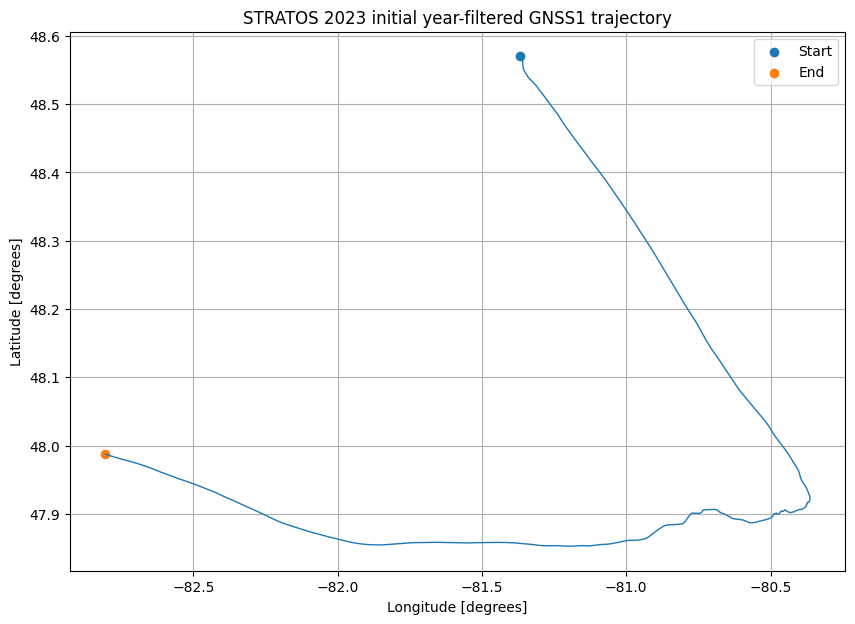

In [13]:
plot_2d_trajectory(
    trajectory_gnss1_initial_2023,
    title="STRATOS 2023 initial year-filtered GNSS1 trajectory",
)

## 10. Detect GNSS1 ellipsoid-height discontinuities

Altitude diagnostics use only 2023 rows in original acquisition order.
Differences are not calculated across backward timestamps or gaps longer than
10 seconds.

In [14]:
altitude_input_gnss1_2023 = (
    diagnostics_gnss1_2023[
        diagnostics_gnss1_2023["parsed_timestamp"].notna()
        & diagnostics_gnss1_2023["expected_year"]
    ]
    .sort_values("original_data_index")
    .reset_index(drop=True)
)

altitude_diagnostics_gnss1_2023 = (
    detect_altitude_discontinuities(
        altitude_input_gnss1_2023,
        step_threshold_m=1000,
        rate_threshold_mps=100,
        rolling_window=11,
        residual_threshold_m=1500,
        max_temporary_segment_samples=20,
        neighbor_tolerance_m=1000,
        max_gap_seconds=10,
    )
)

altitude_candidates_gnss1_2023 = (
    altitude_diagnostics_gnss1_2023[
        altitude_diagnostics_gnss1_2023[
            "altitude_anomaly_candidate"
        ]
    ].copy()
)

altitude_candidate_columns = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "time_step_s",
    "valid_consecutive_step",
    "altitude_step_m",
    "altitude_rate_mps",
    "rolling_altitude_median_m",
    "local_altitude_residual_m",
    "sudden_altitude_transition",
    "temporary_altitude_segment",
    "lat_lon_valid_flag",
]

print(
    "GNSS1 altitude anomaly candidates:",
    len(altitude_candidates_gnss1_2023),
)

display(
    altitude_candidates_gnss1_2023[
        altitude_candidate_columns
    ].head(300)
)

GNSS1 altitude anomaly candidates: 0


,original_data_index,original_csv_row,parsed_timestamp,latitude_numeric,longitude_numeric,altitude_numeric,time_step_s,valid_consecutive_step,altitude_step_m,altitude_rate_mps,rolling_altitude_median_m,local_altitude_residual_m,sudden_altitude_transition,temporary_altitude_segment,lat_lon_valid_flag


### Plot GNSS1 altitude and local-change candidates

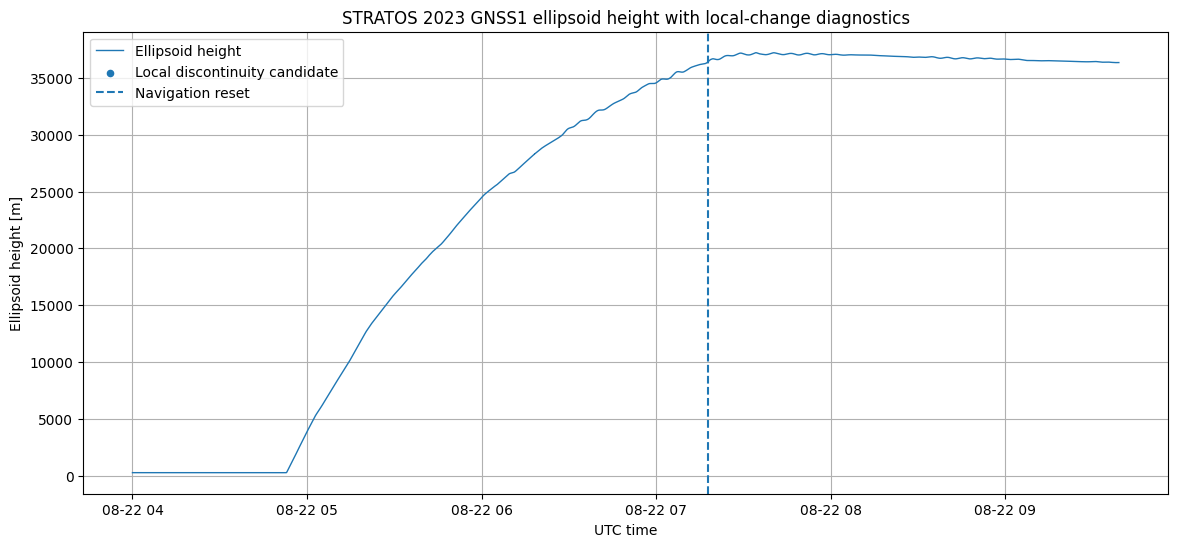

In [15]:
flagged_altitude_gnss1_2023 = (
    altitude_diagnostics_gnss1_2023[
        altitude_diagnostics_gnss1_2023[
            "altitude_anomaly_candidate"
        ]
    ]
)

plt.figure(figsize=(14, 6))
plt.plot(
    altitude_diagnostics_gnss1_2023["parsed_timestamp"],
    altitude_diagnostics_gnss1_2023["altitude_numeric"],
    linewidth=1,
    label="Ellipsoid height",
)
plt.scatter(
    flagged_altitude_gnss1_2023["parsed_timestamp"],
    flagged_altitude_gnss1_2023["altitude_numeric"],
    s=20,
    label="Local discontinuity candidate",
)
plt.axvline(
    NAVIGATION_RESET_TIME,
    linestyle="--",
    label="Navigation reset",
)
plt.xlabel("UTC time")
plt.ylabel("Ellipsoid height [m]")
plt.title(
    "STRATOS 2023 GNSS1 ellipsoid height with local-change diagnostics"
)
plt.legend()
plt.grid(True)
plt.show()

## 11. Detect GNSS1 spatial discontinuities and build the final trajectory

The initially cleaned GNSS1 trajectory is split whenever consecutive positions
differ by more than 100 km. The segment summary is displayed before selection.

In [16]:
(
    final_trajectory_gnss1_2023,
    segmented_trajectory_gnss1_2023,
    segment_summary_gnss1_2023,
    spatial_jump_candidates_gnss1_2023,
    selected_segment_gnss1_2023,
) = select_final_trajectory_segment(
    trajectory_gnss1_initial_2023,
    position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
    auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
)

print(
    "Consecutive GNSS1 position jumps greater than "
    f"{POSITION_JUMP_THRESHOLD_M / 1000:.0f} km:",
    len(spatial_jump_candidates_gnss1_2023),
)

display(
    spatial_jump_candidates_gnss1_2023[
        [
            "original_data_index",
            "original_csv_row",
            "timestamp",
            "latitude",
            "longitude",
            "altitude_m",
            "position_step_km",
            "time_step_s",
            "horizontal_speed_mps",
            "segment_id",
        ]
    ]
)

print("GNSS1 trajectory segment summary:")
display(segment_summary_gnss1_2023)

print("Selected GNSS1 segment ID:", selected_segment_gnss1_2023)
print("Initial cleaned rows:", len(trajectory_gnss1_initial_2023))
print("Final cleaned rows:", len(final_trajectory_gnss1_2023))
print("Final GNSS1 time range:")
print(final_trajectory_gnss1_2023["timestamp"].min())
print(final_trajectory_gnss1_2023["timestamp"].max())

assert not final_trajectory_gnss1_2023.empty
assert final_trajectory_gnss1_2023["timestamp"].dt.year.eq(YEAR).all()
assert ~(
    (final_trajectory_gnss1_2023["latitude"] == 0)
    & (final_trajectory_gnss1_2023["longitude"] == 0)
).any()

Consecutive GNSS1 position jumps greater than 100 km: 0


,original_data_index,original_csv_row,timestamp,latitude,longitude,altitude_m,position_step_km,time_step_s,horizontal_speed_mps,segment_id


GNSS1 trajectory segment summary:


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,0,40626,2023-08-22 04:00:00+00:00,2023-08-22 09:39:03.500000+00:00,47.852557,48.570295,-82.804288,-80.363692,254.302,37220.037


Selected GNSS1 segment ID: 0
Initial cleaned rows: 40626
Final cleaned rows: 40626
Final GNSS1 time range:
2023-08-22 04:00:00+00:00
2023-08-22 09:39:03.500000+00:00


### Inspect rows surrounding every GNSS1 spatial jump

In [17]:
for bad_index in spatial_jump_candidates_gnss1_2023.index:
    start = max(0, bad_index - 6)
    end = min(
        len(segmented_trajectory_gnss1_2023) - 1,
        bad_index + 6,
    )

    print("\n" + "=" * 110)

    display(
        segmented_trajectory_gnss1_2023.loc[
            start:end,
            [
                "original_data_index",
                "original_csv_row",
                "timestamp",
                "latitude",
                "longitude",
                "altitude_m",
                "position_step_km",
                "time_step_s",
                "segment_id",
            ],
        ]
    )

## 12. Visualize the final cleaned GNSS1 trajectory

The same `final_trajectory_gnss1_2023` dataframe is used for both plots and
the final GNSS1 trajectory CSV export.

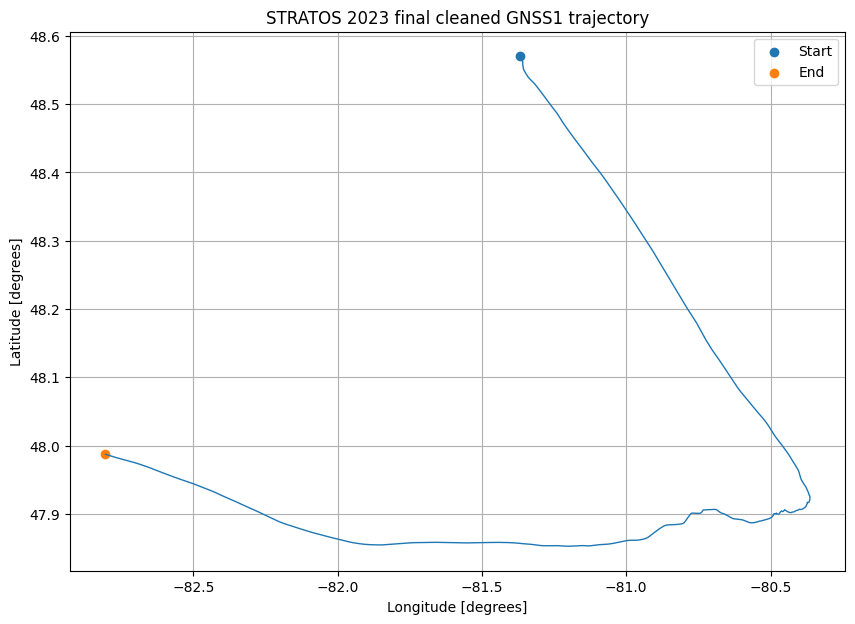

In [18]:
plot_2d_trajectory(
    final_trajectory_gnss1_2023,
    title="STRATOS 2023 final cleaned GNSS1 trajectory",
)

plot_3d_trajectory(
    final_trajectory_gnss1_2023,
    title="STRATOS 2023 final cleaned GNSS1 3D trajectory",
)

## 13. Clean and compare GNSS2

GNSS2 undergoes the same year, coordinate, and spatial-continuity processing
as GNSS1.

GNSS2 timestamp counts by year:


,year,rows
0,1980,49
1,2023,40625


Selected GNSS2 segment ID: 0


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,0,40625,2023-08-22 04:00:00+00:00,2023-08-22 09:39:03.500000+00:00,47.852547,48.570321,-82.804287,-80.363661,254.091,37218.99


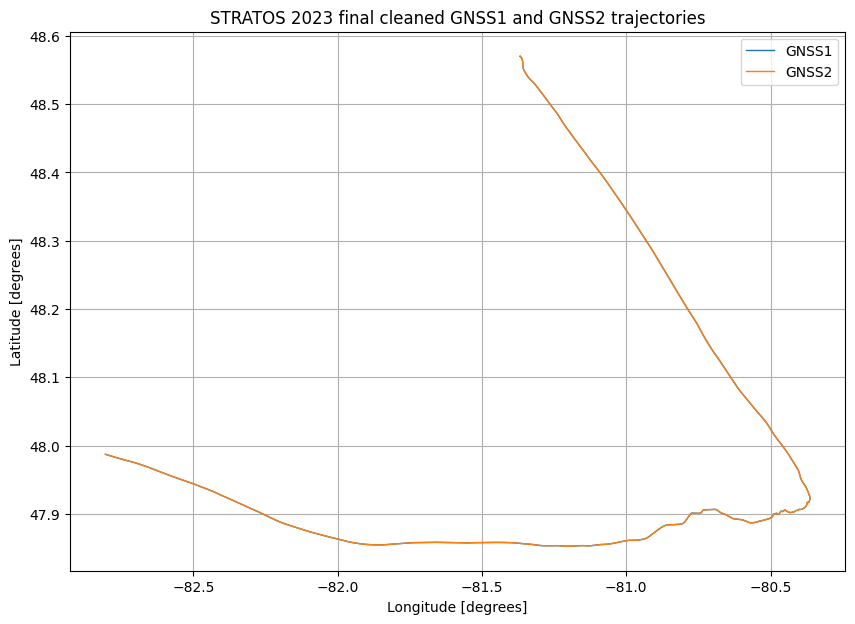

In [19]:
diagnostics_gnss2_2023, trajectory_gnss2_initial_2023 = (
    standardize_trajectory(
        gnss2,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
        require_position_valid_flag=REQUIRE_POSITION_VALID_FLAG,
    )
)

gnss2_timestamp_anomalies_2023 = diagnostics_gnss2_2023[
    diagnostics_gnss2_2023["parsed_timestamp"].notna()
    & ~diagnostics_gnss2_2023["expected_year"]
].copy()

(
    final_trajectory_gnss2_2023,
    segmented_trajectory_gnss2_2023,
    segment_summary_gnss2_2023,
    spatial_jump_candidates_gnss2_2023,
    selected_segment_gnss2_2023,
) = select_final_trajectory_segment(
    trajectory_gnss2_initial_2023,
    position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
    auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
)

print("GNSS2 timestamp counts by year:")
display(
    diagnostics_gnss2_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

print("Selected GNSS2 segment ID:", selected_segment_gnss2_2023)
display(segment_summary_gnss2_2023)

plt.figure(figsize=(10, 7))
plt.plot(
    final_trajectory_gnss1_2023["longitude"],
    final_trajectory_gnss1_2023["latitude"],
    linewidth=1,
    label="GNSS1",
)
plt.plot(
    final_trajectory_gnss2_2023["longitude"],
    final_trajectory_gnss2_2023["latitude"],
    linewidth=1,
    label="GNSS2",
)
plt.xlabel("Longitude [degrees]")
plt.ylabel("Latitude [degrees]")
plt.title("STRATOS 2023 final cleaned GNSS1 and GNSS2 trajectories")
plt.legend()
plt.grid(True)
plt.show()

## 14. Inspect and clean the 25 Hz estimation-filter trajectory

The EF 25 Hz file provides the fused navigation solution. It is cleaned using
the same campaign-year, coordinate, and spatial-continuity logic.

EF 25 Hz timestamp counts by year:


,year,rows
0,2023,507444


Selected EF 25 Hz segment ID: 0


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,0,507444,2023-08-22 04:00:00.002000+00:00,2023-08-22 09:39:03.681000+00:00,47.852561,48.570305,-82.804339,-80.363684,254.232234,37222.296798


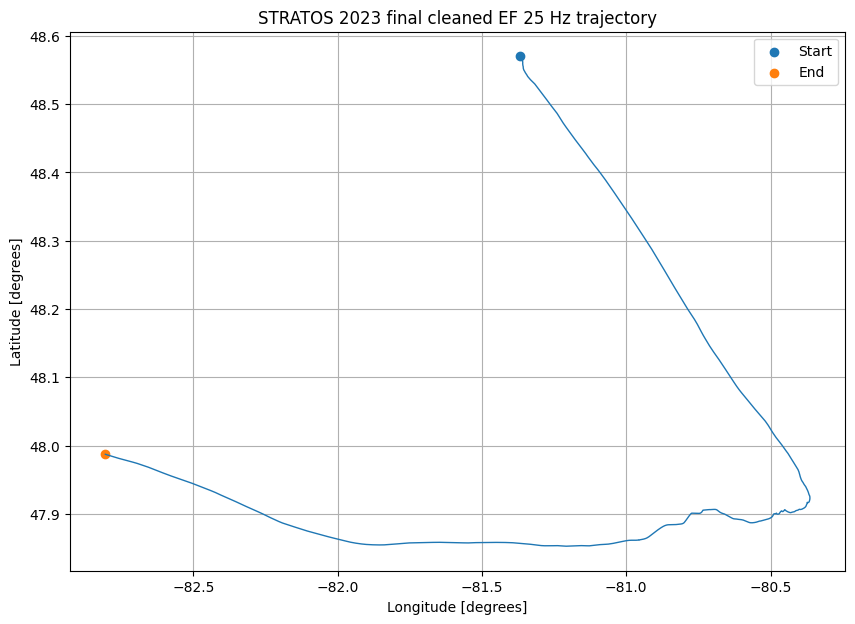

In [20]:
diagnostics_ef25_2023, trajectory_ef25_initial_2023 = (
    standardize_trajectory(
        ef_25hz,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
        require_position_valid_flag=False,
    )
)

ef25_timestamp_anomalies_2023 = diagnostics_ef25_2023[
    diagnostics_ef25_2023["parsed_timestamp"].notna()
    & ~diagnostics_ef25_2023["expected_year"]
].copy()

(
    final_trajectory_ef25_2023,
    segmented_trajectory_ef25_2023,
    segment_summary_ef25_2023,
    spatial_jump_candidates_ef25_2023,
    selected_segment_ef25_2023,
) = select_final_trajectory_segment(
    trajectory_ef25_initial_2023,
    position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
    auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
)

print("EF 25 Hz timestamp counts by year:")
display(
    diagnostics_ef25_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

print("Selected EF 25 Hz segment ID:", selected_segment_ef25_2023)
display(segment_summary_ef25_2023)

plot_2d_trajectory(
    final_trajectory_ef25_2023,
    title="STRATOS 2023 final cleaned EF 25 Hz trajectory",
)

## 15. Inspect and clean the separate environmental dataset

Timestamp anomalies are retained separately. Only 2023 rows are plotted and
exported.

Environmental timestamp counts by year:


,year,rows
0,2023,10172


Available environmental fields: {'CPU temperature [°C]': 'CPU Temp', 'External temperature [°C]': 'External Temp', 'External pressure [hPa]': 'External Press', 'External humidity [%]': 'External Humid'}


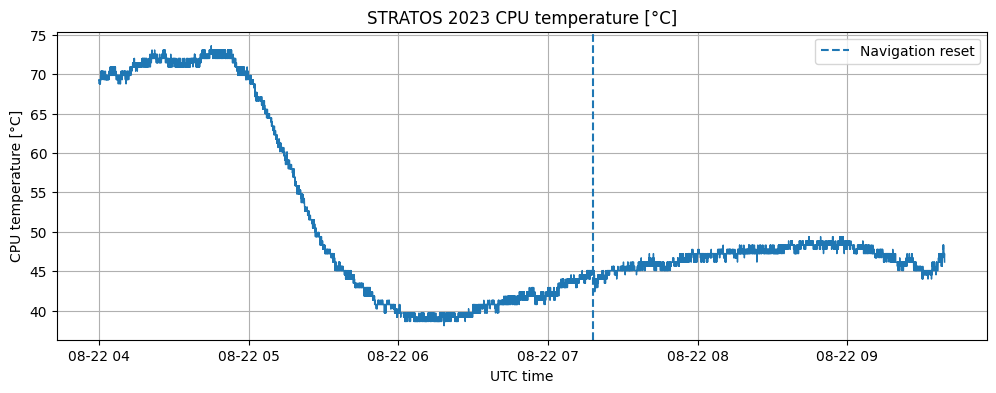

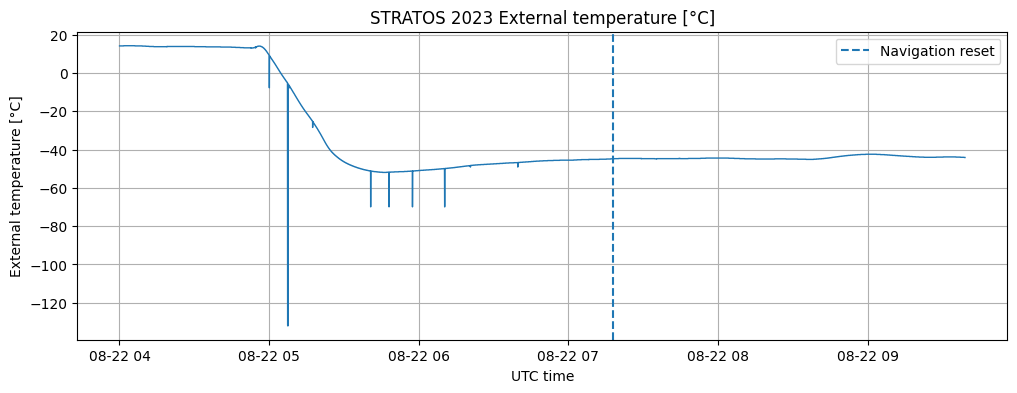

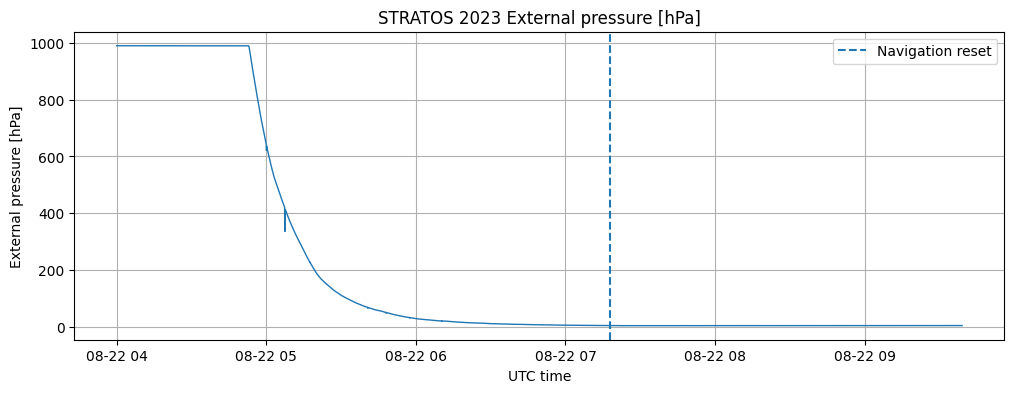

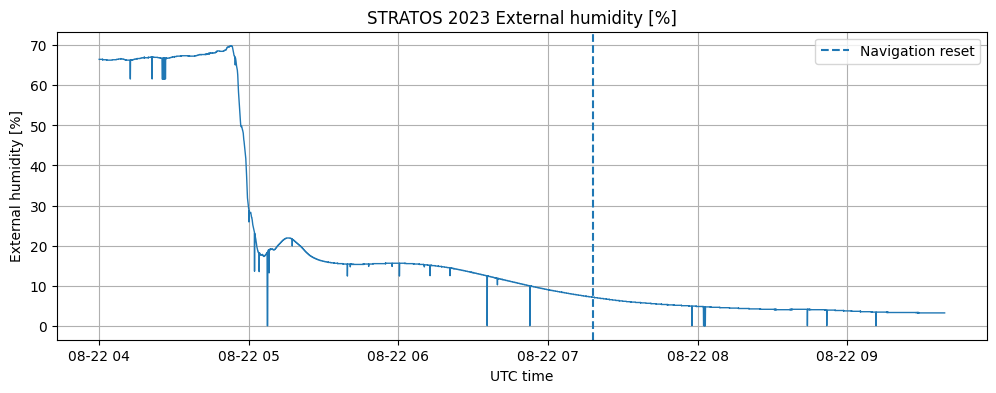

In [21]:
(
    environment_diagnostics_2023,
    environment_timestamp_anomalies_2023,
    environment_2023,
) = prepare_campaign_timeseries(
    environment,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
)

print("Environmental timestamp counts by year:")
display(
    environment_diagnostics_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

environment_fields = {
    "CPU temperature [°C]": ["CPU Temp"],
    "External temperature [°C]": ["External Temp"],
    "External pressure [hPa]": ["External Press"],
    "External humidity [%]": ["External Humid"],
}

environment_plot_columns: dict[str, str] = {}

for label, candidates in environment_fields.items():
    column = find_column(
        environment_2023,
        candidates,
        required=False,
    )

    if column is not None:
        environment_plot_columns[label] = column
        environment_2023[column] = numeric(
            environment_2023[column]
        )

print("Available environmental fields:", environment_plot_columns)

for label, column in environment_plot_columns.items():
    plot_data = environment_2023[
        ["parsed_timestamp", column]
    ].dropna()

    plt.figure(figsize=(12, 4))
    plt.plot(
        plot_data["parsed_timestamp"],
        plot_data[column],
        linewidth=1,
    )
    plt.axvline(
        NAVIGATION_RESET_TIME,
        linestyle="--",
        label="Navigation reset",
    )
    plt.xlabel("UTC time")
    plt.ylabel(label)
    plt.title(f"STRATOS 2023 {label}")
    plt.legend()
    plt.grid(True)
    plt.show()

## 16. Inspect and clean IMU temperature and pressure

Only 2023 timestamps are plotted and exported. GPS-epoch records remain in a
separate anomaly table.

IMU timestamp counts by year:


,year,rows
0,1980,39
1,2023,20296


Available IMU fields: {'Minimum temperature [°C]': 'Min Temp', 'Maximum temperature [°C]': 'Max Temp', 'Mean temperature [°C]': 'Mean Temp', 'Pressure [mbar]': 'Pressure'}


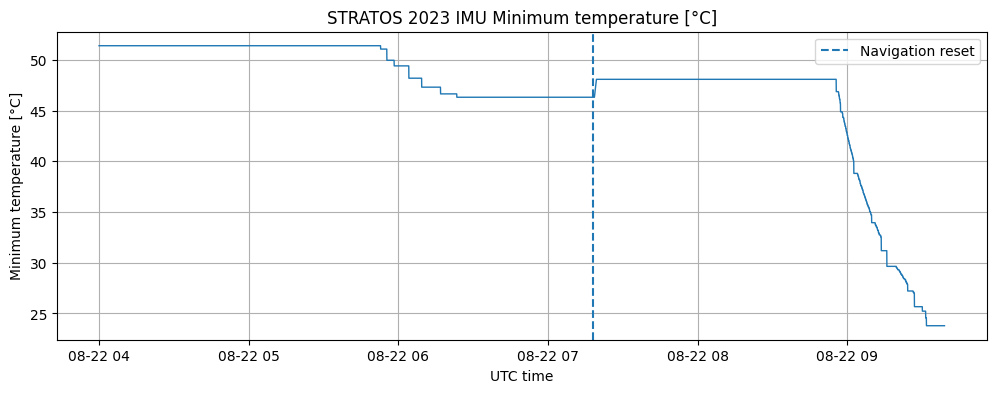

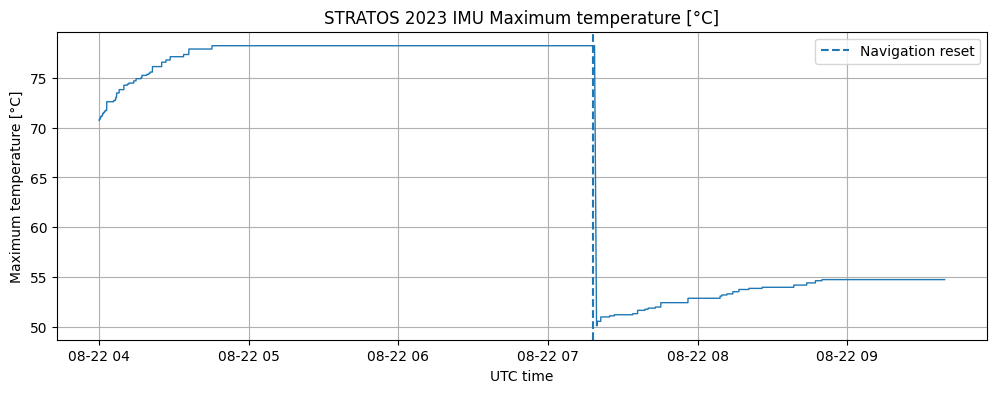

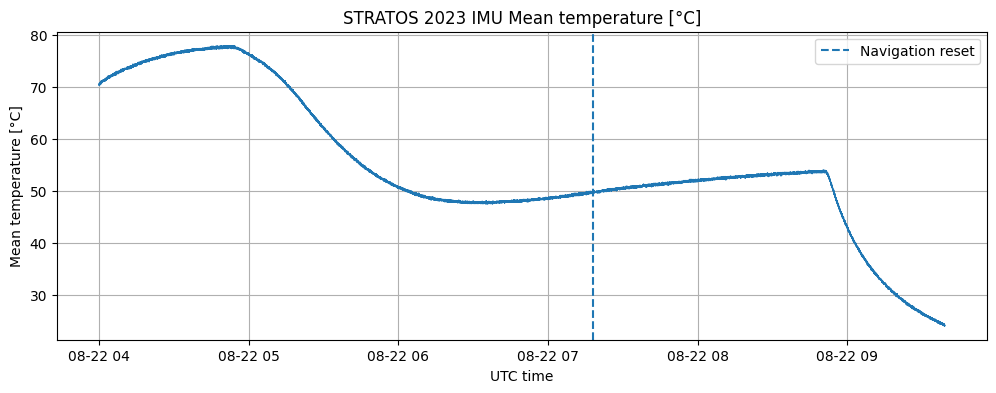

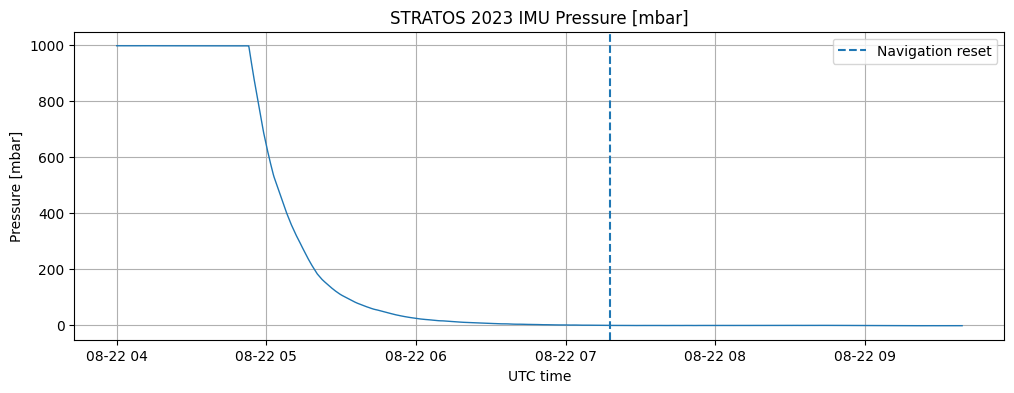

In [22]:
(
    imu_diagnostics_2023,
    imu_timestamp_anomalies_2023,
    imu_2023,
) = prepare_campaign_timeseries(
    imu,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
)

print("IMU timestamp counts by year:")
display(
    imu_diagnostics_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

imu_fields = {
    "Minimum temperature [°C]": [
        "Min Temp",
        "Minimum Temp",
    ],
    "Maximum temperature [°C]": [
        "Max Temp",
        "Maximum Temp",
    ],
    "Mean temperature [°C]": [
        "Mean Temp",
        "Mean Temperature",
    ],
    "Pressure [mbar]": ["Pressure"],
}

imu_plot_columns: dict[str, str] = {}

for label, candidates in imu_fields.items():
    column = find_column(
        imu_2023,
        candidates,
        required=False,
    )

    if column is not None:
        imu_plot_columns[label] = column
        imu_2023[column] = numeric(imu_2023[column])

print("Available IMU fields:", imu_plot_columns)

for label, column in imu_plot_columns.items():
    plot_data = imu_2023[
        ["parsed_timestamp", column]
    ].dropna()

    plt.figure(figsize=(12, 4))
    plt.plot(
        plot_data["parsed_timestamp"],
        plot_data[column],
        linewidth=1,
    )
    plt.axvline(
        NAVIGATION_RESET_TIME,
        linestyle="--",
        label="Navigation reset",
    )
    plt.xlabel("UTC time")
    plt.ylabel(label)
    plt.title(f"STRATOS 2023 IMU {label}")
    plt.legend()
    plt.grid(True)
    plt.show()

## 17. Inspect and clean track angle

Only 2023 timestamps are plotted and exported. The validity flag distribution
is reported separately.

Track-angle timestamp counts by year:


,year,rows
0,2023,20336


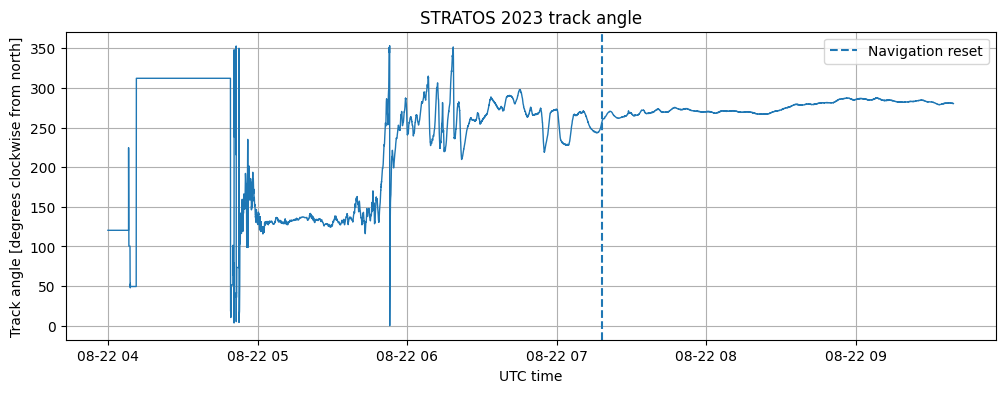

,validity value,rows
0,1,15880
1,0,4456


In [23]:
(
    track_diagnostics_2023,
    track_timestamp_anomalies_2023,
    track_2023,
) = prepare_campaign_timeseries(
    track,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
)

track_angle_col = find_column(
    track_2023,
    ["Track Angle"],
    required=True,
)
track_valid_col = find_column(
    track_2023,
    ["Track Angle Valid"],
    required=False,
)

track_2023["track_angle_numeric"] = numeric(
    track_2023[track_angle_col]
)

print("Track-angle timestamp counts by year:")
display(
    track_diagnostics_2023["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

plt.figure(figsize=(12, 4))
plt.plot(
    track_2023["parsed_timestamp"],
    track_2023["track_angle_numeric"],
    linewidth=1,
)
plt.axvline(
    NAVIGATION_RESET_TIME,
    linestyle="--",
    label="Navigation reset",
)
plt.xlabel("UTC time")
plt.ylabel("Track angle [degrees clockwise from north]")
plt.title("STRATOS 2023 track angle")
plt.legend()
plt.grid(True)
plt.show()

if track_valid_col is not None:
    display(
        track_2023[track_valid_col]
        .value_counts(dropna=False)
        .rename_axis("validity value")
        .reset_index(name="rows")
    )

## 18. NMEA inspection

Enable `LOAD_NMEA` in the configuration section, then rerun the loading cells.
The NMEA file is preserved line by line rather than forced into the same tabular
schema as the other uPRISM exports.

In [24]:
if LOAD_NMEA:
    nmea = tables["nmea"]
    print("NMEA lines:", len(nmea))
    display(nmea.head(50))
else:
    print(
        "NMEA file not loaded. Set LOAD_NMEA = True and rerun "
        "the loading cells."
    )

NMEA file not loaded. Set LOAD_NMEA = True and rerun the loading cells.


## 19. 500 Hz estimation-filter inspection

Enable `LOAD_500_HZ` in the configuration section only when sufficient memory
and download time are available. The file is cleaned and heavily downsampled
for plotting.

In [25]:
if LOAD_500_HZ:
    ef_500hz = tables["ef_500hz"]

    diagnostics_ef500_2023, trajectory_ef500_initial_2023 = (
        standardize_trajectory(
            ef_500hz,
            expected_year=YEAR,
            flight_date=FLIGHT_DATE,
            require_position_valid_flag=False,
        )
    )

    ef500_timestamp_anomalies_2023 = diagnostics_ef500_2023[
        diagnostics_ef500_2023["parsed_timestamp"].notna()
        & ~diagnostics_ef500_2023["expected_year"]
    ].copy()

    (
        final_trajectory_ef500_2023,
        segmented_trajectory_ef500_2023,
        segment_summary_ef500_2023,
        spatial_jump_candidates_ef500_2023,
        selected_segment_ef500_2023,
    ) = select_final_trajectory_segment(
        trajectory_ef500_initial_2023,
        position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
        auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
    )

    max_plot_points = 20_000
    plot_step = max(
        1,
        math.ceil(
            len(final_trajectory_ef500_2023)
            / max_plot_points
        ),
    )
    ef500_plot = final_trajectory_ef500_2023.iloc[
        ::plot_step
    ]

    print("500 Hz raw rows:", len(ef_500hz))
    print(
        "500 Hz final cleaned rows:",
        len(final_trajectory_ef500_2023),
    )
    display(segment_summary_ef500_2023)

    plt.figure(figsize=(12, 4))
    plt.plot(
        ef500_plot["timestamp"],
        ef500_plot["altitude_m"],
        linewidth=1,
    )
    plt.xlabel("UTC time")
    plt.ylabel("Altitude [m]")
    plt.title(
        "STRATOS 2023 500 Hz EF altitude — downsampled display"
    )
    plt.grid(True)
    plt.show()
else:
    print(
        "500 Hz file not loaded. Set LOAD_500_HZ = True and "
        "rerun the loading cells."
    )

500 Hz file not loaded. Set LOAD_500_HZ = True and rerun the loading cells.


## 20. Export final cleaned data and diagnostics

The final GNSS1 trajectory CSV is created from
`final_trajectory_gnss1_2023`, the same dataframe used in its final plots.
Optional NMEA and 500 Hz exports are added only when those files were loaded.

In [26]:
OUTPUT_DIR = Path("tutorial_outputs_2023")
OUTPUT_DIR.mkdir(exist_ok=True)

export_files = {
    "gnss1_final_trajectory": (
        final_trajectory_gnss1_2023,
        OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2023.csv",
    ),
    "gnss1_timestamp_anomalies": (
        gnss1_timestamp_anomalies_2023,
        OUTPUT_DIR / "gnss1_timestamp_anomalies_2023.csv",
    ),
    "gnss1_anomaly_blocks": (
        gnss1_anomaly_blocks_2023,
        OUTPUT_DIR / "gnss1_timestamp_anomaly_blocks_2023.csv",
    ),
    "gnss1_altitude_candidates": (
        altitude_candidates_gnss1_2023,
        OUTPUT_DIR / "gnss1_altitude_anomaly_candidates_2023.csv",
    ),
    "gnss1_spatial_jump_candidates": (
        spatial_jump_candidates_gnss1_2023,
        OUTPUT_DIR / "gnss1_spatial_jump_candidates_2023.csv",
    ),
    "gnss1_trajectory_segments": (
        segment_summary_gnss1_2023,
        OUTPUT_DIR / "gnss1_trajectory_segments_2023.csv",
    ),
    "gnss2_final_trajectory": (
        final_trajectory_gnss2_2023,
        OUTPUT_DIR / "gnss2_final_cleaned_trajectory_2023.csv",
    ),
    "gnss2_timestamp_anomalies": (
        gnss2_timestamp_anomalies_2023,
        OUTPUT_DIR / "gnss2_timestamp_anomalies_2023.csv",
    ),
    "gnss2_spatial_jump_candidates": (
        spatial_jump_candidates_gnss2_2023,
        OUTPUT_DIR / "gnss2_spatial_jump_candidates_2023.csv",
    ),
    "gnss2_trajectory_segments": (
        segment_summary_gnss2_2023,
        OUTPUT_DIR / "gnss2_trajectory_segments_2023.csv",
    ),
    "ef25_final_trajectory": (
        final_trajectory_ef25_2023,
        OUTPUT_DIR / "ef25_final_cleaned_trajectory_2023.csv",
    ),
    "ef25_timestamp_anomalies": (
        ef25_timestamp_anomalies_2023,
        OUTPUT_DIR / "ef25_timestamp_anomalies_2023.csv",
    ),
    "ef25_spatial_jump_candidates": (
        spatial_jump_candidates_ef25_2023,
        OUTPUT_DIR / "ef25_spatial_jump_candidates_2023.csv",
    ),
    "ef25_trajectory_segments": (
        segment_summary_ef25_2023,
        OUTPUT_DIR / "ef25_trajectory_segments_2023.csv",
    ),
    "environment_cleaned": (
        environment_2023,
        OUTPUT_DIR / "environment_cleaned_2023.csv",
    ),
    "environment_timestamp_anomalies": (
        environment_timestamp_anomalies_2023,
        OUTPUT_DIR / "environment_timestamp_anomalies_2023.csv",
    ),
    "imu_cleaned": (
        imu_2023,
        OUTPUT_DIR / "imu_cleaned_2023.csv",
    ),
    "imu_timestamp_anomalies": (
        imu_timestamp_anomalies_2023,
        OUTPUT_DIR / "imu_timestamp_anomalies_2023.csv",
    ),
    "track_cleaned": (
        track_2023,
        OUTPUT_DIR / "track_angle_cleaned_2023.csv",
    ),
    "track_timestamp_anomalies": (
        track_timestamp_anomalies_2023,
        OUTPUT_DIR / "track_angle_timestamp_anomalies_2023.csv",
    ),
}

if LOAD_NMEA:
    export_files["nmea_raw_lines"] = (
        nmea,
        OUTPUT_DIR / "nmea_raw_lines_2023.csv",
    )

if LOAD_500_HZ:
    export_files.update(
        {
            "ef500_final_trajectory": (
                final_trajectory_ef500_2023,
                OUTPUT_DIR
                / "ef500_final_cleaned_trajectory_2023.csv",
            ),
            "ef500_timestamp_anomalies": (
                ef500_timestamp_anomalies_2023,
                OUTPUT_DIR / "ef500_timestamp_anomalies_2023.csv",
            ),
            "ef500_spatial_jump_candidates": (
                spatial_jump_candidates_ef500_2023,
                OUTPUT_DIR
                / "ef500_spatial_jump_candidates_2023.csv",
            ),
            "ef500_trajectory_segments": (
                segment_summary_ef500_2023,
                OUTPUT_DIR / "ef500_trajectory_segments_2023.csv",
            ),
        }
    )

export_summary_rows = []

for label, (frame, path) in export_files.items():
    frame.to_csv(path, index=False)

    export_summary_rows.append(
        {
            "export": label,
            "rows": len(frame),
            "columns": len(frame.columns),
            "path": str(path.resolve()),
        }
    )

export_summary_2023 = pd.DataFrame(export_summary_rows)
display(export_summary_2023)

print("Saved files to:", OUTPUT_DIR.resolve())

,export,rows,columns,path
0,gnss1_final_trajectory,40626,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_final_cleaned_traj...
1,gnss1_timestamp_anomalies,49,78,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_timestamp_anomalie...
2,gnss1_anomaly_blocks,1,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_timestamp_anomaly_...
3,gnss1_altitude_candidates,0,88,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_altitude_anomaly_c...
4,gnss1_spatial_jump_candidates,0,13,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_spatial_jump_candi...
5,gnss1_trajectory_segments,1,10,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss1_trajectory_segment...
6,gnss2_final_trajectory,40625,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss2_final_cleaned_traj...
7,gnss2_timestamp_anomalies,49,78,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss2_timestamp_anomalie...
8,gnss2_spatial_jump_candidates,0,13,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss2_spatial_jump_candi...
9,gnss2_trajectory_segments,1,10,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023\gnss2_trajectory_segment...


Saved files to: C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2023


## 21. Final consistency checks

These checks confirm that the final GNSS1 trajectory used for plotting and
export contains only 2023 timestamps, excludes `(0°, 0°)`, and matches the
exported row count. The other cleaned time-series exports are also checked for
campaign-year timestamps.

In [27]:
final_gnss1_export_path = (
    OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2023.csv"
)
final_gnss1_export_check = pd.read_csv(
    final_gnss1_export_path
)

assert (
    len(final_gnss1_export_check)
    == len(final_trajectory_gnss1_2023)
)
assert (
    final_trajectory_gnss1_2023["timestamp"]
    .dt.year
    .eq(YEAR)
    .all()
)
assert ~(
    (final_trajectory_gnss1_2023["latitude"] == 0)
    & (final_trajectory_gnss1_2023["longitude"] == 0)
).any()

for label, frame in {
    "GNSS2": final_trajectory_gnss2_2023,
    "EF 25 Hz": final_trajectory_ef25_2023,
}.items():
    assert frame["timestamp"].dt.year.eq(YEAR).all(), label
    assert ~(
        (frame["latitude"] == 0)
        & (frame["longitude"] == 0)
    ).any(), label

for label, frame in {
    "environment": environment_2023,
    "IMU": imu_2023,
    "track angle": track_2023,
}.items():
    assert frame["parsed_timestamp"].dt.year.eq(YEAR).all(), label

print("Final consistency checks passed.")
print(
    "Final GNSS1 trajectory rows:",
    len(final_trajectory_gnss1_2023),
)
print(
    "Exported GNSS1 trajectory rows:",
    len(final_gnss1_export_check),
)

Final consistency checks passed.
Final GNSS1 trajectory rows: 40626
Exported GNSS1 trajectory rows: 40626


## Conclusions

- Raw source tables remain unchanged for traceability.
- GPS-epoch timestamp rows are reported and excluded only from derived 2023
  views.
- `(0°, 0°)` GNSS placeholders do not define the flight origin.
- GNSS1, GNSS2, and EF 25 Hz trajectories use the same campaign-year,
  coordinate, and spatial-continuity framework.
- Navigation-reset context is preserved in plots and anomaly-block summaries.
- Environmental, IMU, and track-angle plots use only 2023 timestamps.
- The 500 Hz EF file remains optional because of its size.
- `final_trajectory_gnss1_2023` is used consistently for the final GNSS1 2D
  plot, final 3D plot, and final GNSS1 trajectory CSV export.
- All anomaly tables and segment summaries remain available for scientific
  review and audit.